# The f01 jump model: drift, staleness and setpoint

## Overview
Every calibrate_1q run measures each qubit's f01 and applies the new value. This notebook builds a model of how that value changes between runs ([Phase 02, D2](../../docs/phases/02_hypotheses.md#d2-f01-dynamics)). We use it for two things: how stale a calibration gets, and whether a filtered value is a better setpoint than the last measurement.

**Hypothesis.** f01 drifts slowly, with rare level jumps and single-run outliers. A model with both says how stale a calibration gets, and its filtered level is a better setpoint than each new measurement.

**Question.** [C2](../02_temporal/c2_1q_params.ipynb) finds that f01 drifts slowly within strata, but the change between runs has heavy tails (section 1). Does a model with jumps and outliers fit better, predict the next run better and predict the change over two weeks? Does its level make a better setpoint?

**Method.** Part 1 builds the series (section 1), defines the model (section 2) and fits it in and out of sample (sections 3 and 4). It compares the predicted change over $L$ runs with the data (section 5), labels each run (section 6) and checks how f01 averages over time (section 7). Part 2 adds the FineFrequency stage and a pull-back (sections 8 to 12), checks whether the parameters change over time (section 13), replays the setpoint rules (section 14) and refits per window (section 15).

**Jumps and outliers.** A **level jump** moves f01 and the next run stays at the new level. An **outlier** is one bad applied value, and the next run goes back. A histogram of changes can't separate them, but the next run can.

<details>
<summary><b>The models</b></summary>

We fit all models per qubit by maximum likelihood. The equations are in sections 2 and 9.

- **M0 Gaussian.** The level $x$ is a random walk with variance $q$ per day. The applied value is $y = x + e$, with $e$ white noise of variance $R$.
- **M1 jumps.** M0 plus level jumps, with sizes on a log grid and one rate per day for each size.
- **M2 outliers.** M0 plus single-run outliers, with sizes on a log grid and one probability per run for each size.
- **M3 both.** Jumps and outliers together.
- **M3s stage noise.** M3, with $R$ multiplied by $m_1$ when the run stopped one FineFrequency step short of the full ladder, and by $m_2$ when it stopped two or more short.
- **M4 pull-back.** M3, with the level split into a baseline and a deviation that decays back to it with time constant $\tau$. A share $w$ of each jump goes to the deviation. So $w = 0$ is M3's lasting jump and $w = 1$ is a jump that fully decays.
- **M4s.** M3s and M4 together.

</details>

**Data.** The run map and the B3c noise floor, which we use only for comparison. The clean rows and segments are those of [d1a](d1a_f01_shared_vs_local.ipynb), section 1. The producer code is calibrate_1q.py in oqc-calibration-routines, and Ramsey and FineFrequency in oqc-maac (maac/measurement/cal_1q.py).


In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import jumps, methods, series
from qpu_drift.analysis.constants import MIN_N
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.derived.run_map import load_run_entities, load_run_map
from qpu_drift.paths import REPO_ROOT

pd.set_option(
    "display.max_rows",
    200,
    "display.max_columns",
    30,
    "display.width",
    250,
    "display.max_colwidth",
    120,
)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

# Test rows before and after this date are also scored apart (section 4)
CYCLE_START = periods.THERMAL_CYCLES[0][0]

# How stale a calibration gets (section 5)
LAGS = [1, 2, 4, 14, 28]  # runs: half a day to two weeks
K_TAIL = [3, 5, 10, 30]  # exceedance thresholds in units of the qubit's lag-1 robust sd
N_SIM = 100  # simulated paths per qubit

# Posterior probability that labels a run a jump or an outlier (section 6)
P_CLASS = 0.5

# Allan deviation (section 7)
ADEV_M = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]  # averaging lengths in rows
STRETCH_GAP = pd.Timedelta("36h")  # rows further apart start a new stretch, as lag_pairs
ADEV_MIN_INDEP = 5  # differences a qubit needs at m, in units of m
N_BOOT = 2000  # qubit resamples behind each interval

# Where the filter restarts: incident starts and untracked DS2 writes that touched calibrate_1q
INCIDENT_STARTS = [i.period[0] for i in periods.INCIDENTS]
U1 = [u.at for u in periods.UNTRACKED_DS2 if "calibrate_1q" in u.routines]
CUTS = INCIDENT_STARTS + U1

rng = np.random.default_rng(0)

## 1. The series

We take one row per qubit and calibrate_1q run that changed f01, with the set-up of d1a, section 1. Each row holds the applied value, its stratum and segment, and `warned`. A run is `warned` when a FineFrequency step failed, so an earlier step's value was applied (A3). A qubit enters once it has MIN_N clean rows. Q2, Q8 and Q13 have almost no clean rows (B3a).

The change into run $t$ is $d_t = y_t - y_{t-1}$ in kHz, within a segment. For each qubit we report the robust sd of $d_t$, its excess kurtosis, and the share of $\sum_t d_t^2$ in steps above 6 robust sd. A large step **reverts** when the next step goes back by at least half of it:

$$\operatorname{sign} d_{t+1} \ne \operatorname{sign} d_t \quad\text{and}\quad \lvert d_{t+1}\rvert > \tfrac12 \lvert d_t\rvert .$$

Reverting is the sign of an outlier. We also report the share of large steps that are `warned`.


In [2]:
# The applied f01 of every calibrate_1q run, one row per qubit and run
runs1q = load_run_map(routine="calibrate_1q")
rows = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)
keep_cols = ["qubit", "run", "t", "value", "old", "warned", "incident", "f01_flag", "stratum"]
f = rows.loc[rows["param"] == "freq", keep_cols]
f = f.rename(columns={"value": "y_hz"}).sort_values(["qubit", "run"], ignore_index=True)
f["settling"] = f["stratum"] == "settling"

# Segment: the stratum, split by the number of cuts before the row
cuts_sorted = np.sort(np.array(CUTS, dtype="datetime64[ns]"))
cut_no = np.searchsorted(cuts_sorted, f["t"].to_numpy("datetime64[ns]"), side="left")
f["seg"] = f["stratum"] + " c" + pd.Series(cut_no).astype(str)

# The B3c fit sd of freq per qubit and stratum, for comparison
sig = series.ds1_1q_noise(load_noise_floor()).xs("freq", level="param")["sigma"].rename("sigma")
f = f.join(sig, on=["qubit", "stratum"])

# Clean rows (no incident, f01 flag or settling), on qubits with at least MIN_N of them
clean = f[~(f["incident"] | f["f01_flag"] | f["settling"])].copy()
n_q = clean.groupby("qubit").size()
clean = clean[clean["qubit"].isin(n_q[n_q >= MIN_N].index)].sort_values(
    ["qubit", "t"], ignore_index=True
)
clean["warned"] = clean["warned"].astype("boolean").fillna(False).astype(bool)

# f01 in kHz from the segment's first value, and the change into and out of each run
first = clean.groupby(["qubit", "seg"])["y_hz"].transform("first")
clean["y"] = (clean["y_hz"] - first) / 1e3
clean["d"] = clean.groupby(["qubit", "seg"])["y"].diff()
clean["d_next"] = clean.groupby(["qubit", "seg"])["d"].shift(-1)

left_out = sorted(set(n_q.index) - set(clean["qubit"]))
t_first, t_last = clean["t"].min(), clean["t"].max()
print(
    f"applied f01 rows {len(f)} -> clean {len(clean)}, qubits {clean['qubit'].nunique()} "
    f"(left out with under {MIN_N} clean rows: {left_out}), "
    f"segments {clean['seg'].nunique()}, {t_first:%Y-%m-%d} to {t_last:%Y-%m-%d}"
)
print(f"warned rows {int(clean['warned'].sum())} ({clean['warned'].mean():.1%})")


def tail_row(d: np.ndarray) -> dict:
    """Tail statistics of one qubit's increments (kHz)."""
    s = methods.rsd(d)
    big = np.abs(d) > 6 * s
    return {
        "steps": len(d),
        "rsd_kHz": s,
        "kurtosis": pd.Series(d).kurt(),
        "steps_over_6rsd": int(big.sum()),
        "ss_share_over_6rsd": (d[big] ** 2).sum() / (d**2).sum(),
        "max_abs_kHz": np.abs(d).max(),
    }


# Tail statistics per qubit, shown as the median over qubits
tails = pd.DataFrame({q: tail_row(g["d"].dropna().to_numpy()) for q, g in clean.groupby("qubit")}).T
tails["sigma_B3c_kHz"] = clean.groupby("qubit")["sigma"].median() / 1e3
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tails.median().rename("median over qubits").to_frame().T)

# Large steps: how many, on how many qubits, how often the next step undoes them, how often warned
steps = clean.dropna(subset=["d"])
by_size = {}
for thr in [30, 100, 300, 1000]:
    b = steps[steps["d"].abs() > thr]
    flips = np.sign(b["d_next"]) != np.sign(b["d"])
    rev = flips & (b["d_next"].abs() > 0.5 * b["d"].abs())
    by_size[f"|d| > {thr} kHz"] = {
        "steps": len(b),
        "qubits": b["qubit"].nunique(),
        "reverts": rev.mean(),
        "warned": b["warned"].mean(),
    }
by_size["all steps"] = {
    "steps": len(steps),
    "qubits": steps["qubit"].nunique(),
    "reverts": np.nan,
    "warned": steps["warned"].mean(),
}
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(by_size).T)

applied f01 rows 37882 -> clean 37038, qubits 30 (left out with under 20 clean rows: [2, 8, 13]), segments 16, 2024-03-21 to 2026-08-18
warned rows 1716 (4.6%)


,steps,rsd_kHz,kurtosis,steps_over_6rsd,ss_share_over_6rsd,max_abs_kHz,sigma_B3c_kHz
median over qubits,1.23e+03,6.26,553,33,0.982,2.27e+03,2.19


,steps,qubits,reverts,warned
|d| > 30 kHz,2.73e+03,30,0.428,0.361
|d| > 100 kHz,913,29,0.403,0.533
|d| > 300 kHz,232,27,0.397,0.629
|d| > 1000 kHz,61,20,0.23,0.459
all steps,3.66e+04,30,NaN,0.0463


**Results.**

- 37,038 of 37,882 applied f01 rows are clean, on 30 qubits and 16 segments, from 2024-03-21 to 2026-08-18. 4.6% of rows are warned.
- Medians over qubits: the lag-1 robust sd is 6.26 kHz, against a B3c fit sd of 2.19 kHz. The excess kurtosis is 553, and steps above 6 robust sd hold 0.982 of the sum of squares.
- There are 913 steps above 100 kHz on 29 qubits. 0.403 of them revert and 0.533 are warned, against 0.0463 warned over all steps.


## 2. The model and its filter

Let $x_t$ be the qubit's f01 level at run $t$, $y_t$ the applied value, and $\Delta t$ the days since the qubit's previous clean run in the segment. The level drifts and sometimes jumps. The applied value adds noise and is sometimes an outlier:

$$x_t = x_{t-1} + w_t + j_t, \qquad w_t \sim \mathcal{N}(0,\, q\,\Delta t),$$

$$y_t = x_t + e_t + o_t, \qquad e_t \sim \mathcal{N}(0,\, R).$$

M0 has no jumps or outliers. Section 1 shows steps from tens of kHz to a few MHz, which one Gaussian can't cover. So jump and outlier sizes are mixtures on a log grid, $s_k \in \{1, 10, 100\}$, times a base scale $J$ or $O$.

- **Jumps.** Jumps of scale $k$ come at a rate $\lambda_k$ per day, with at most one per interval, and $j_t \sim \mathcal{N}\big(0, (s_k J)^2\big)$.
- **Outliers.** An outlier of scale $k$ happens with probability $r_k$ per run, and $o_t \sim \mathcal{N}\big(0, (s_k O)^2\big)$.

A filter gives each run's predictive density $p(y_t \mid y_{<t})$, its probability of being a jump or an outlier, and a PIT value for the interval checks. We compare models by AIC and BIC, with $k = 2, 6, 6, 10$ parameters and $n$ scored rows:

$$\text{AIC} = 2k - 2\log L, \qquad \text{BIC} = k \ln n - 2 \log L, \qquad \log L = \sum_t \log p(y_t \mid y_{<t}).$$

<details>
<summary><b>Filter, fitting and code</b></summary>

**Filter.** If the level after run $t-1$ has mean $m$ and variance $P$, the predictive density is a mixture over the jump component $a$ and the outlier component $b$:

$$p(y_t \mid y_{<t}) = \sum_{a,b} \pi_a\,\pi_b\;\mathcal{N}\big(y_t;\, m,\, S_{ab}\big), \qquad S_{ab} = P + q\,\Delta t + v_a + R + u_b.$$

$\pi_a \pi_b$ are the prior weights, and $v_a$ and $u_b$ the jump and outlier variances. With $\Lambda = \sum_k \lambda_k$, an interval has no jump with probability $e^{-\Lambda \Delta t}$. Each component gets a Kalman update, and the mixture is replaced by one Gaussian of the same mean and variance (the GPB1 filter).

- **Segments.** The filter restarts at the first row of each segment, with $m = y_t$ and $P = R$. That row adds nothing to the likelihood.
- **Lag-1 posterior.** At the run, a jump and an outlier look the same. At the next run, a jump stays and an outlier goes back. So we update each run's component probabilities with the next run's density, which gives $P(\text{jump}_t \mid y_{\le t+1})$ and $P(\text{outlier}_t \mid y_{\le t+1})$.
- **PIT.** The predictive CDF at the observed value:

$$u_t = \sum_{a,b} \pi_a\,\pi_b\;\Phi\!\left(\frac{y_t - m}{\sqrt{S_{ab}}}\right).$$

**Fitting.** A coordinate search per qubit in log units (logit for $r_k$), with numpy only. Each sweep tries 9 values of one parameter and keeps the best, and the range halves when the best is inside it. There are 8 sweeps from a half-width of 2. Starting values come from the lag-1 robust sd. M1 and M2 start from M0, and M3 from M1 and M2.

**Code.** `qpu_drift.analysis.jumps` (`run_filter`, `fit` and `simulate`). tests/analysis/test_analysis.py checks that M0 is a plain Kalman filter, that the extensions of section 9 reduce to M3 when switched off, and that the lag-1 posterior labels a clear outlier and a clear jump.

</details>


In [3]:
# Part 1 uses M0 to M3; each model fits R and q plus its own extra parameters
MODELS = {m: jumps.MODELS[m] for m in ["M0", "M1", "M2", "M3"]}
NAMES = {"M0": "Gaussian", "M1": "jumps", "M2": "outliers", "M3": "jumps + outliers"}


def fit_all(data: dict, s1: np.ndarray) -> tuple[dict, dict]:
    """Fit M0 to M3; s1 is each qubit's lag-1 robust sd (kHz).

    M0 starts from moments, M1 and M2 from M0, and M3 from M1 and M2.
    """
    one = np.ones_like(s1)
    th, ll = {}, {}

    # M0 from the lag-1 robust sd
    th0 = {"R": np.log(s1 / np.sqrt(2) * 0.9), "q": np.log(0.3 * s1)}
    th["M0"], ll["M0"] = jumps.fit(data, "M0", th0)

    # M1: M0 plus jumps at 0.01 per day per scale, with J at 3 s1
    lam0 = {n: np.log(0.01) * one for n in jumps.LAM}
    th["M1"], ll["M1"] = jumps.fit(data, "M1", th["M0"] | lam0 | {"J": np.log(3 * s1)})

    # M2: M0 plus outliers at logit -5.3 (about 0.005 per run) per scale, with O at 3 s1
    r0 = {n: -5.3 * one for n in jumps.RK}
    th["M2"], ll["M2"] = jumps.fit(data, "M2", th["M0"] | r0 | {"O": np.log(3 * s1)})

    # M3: M1's fit plus M2's outlier parameters
    outliers = {n: th["M2"][n] for n in (*jumps.RK, "O")}
    th["M3"], ll["M3"] = jumps.fit(data, "M3", th["M1"] | outliers)
    return th, ll

## 3. In-sample fit

We fit every model once per qubit on all clean rows. We report the parameters as sds in kHz:

- $\sqrt{R}$ is the white noise of the applied value.
- $\sqrt{q}$ is the random-walk step per day.
- $J$ and $O$ are the base jump and outlier scales. The grid adds $10\times$ and $100\times$ these.

Jump rates are per 30 days and outlier rates per 100 runs. We compare $\sqrt{R}$ with the B3c fit sd. B3c and C2 find that the fit sd misses part of the scatter within a run, so $\sqrt{R}$ should be somewhat above it.

Per qubit we take $\Delta\text{AIC}$ and $\Delta\text{BIC}$ against M0, where a negative value favours the larger model. We also count the best model by AIC and by BIC.

In [4]:
# Each qubit's lag-1 robust sd sets the starting values
s1 = clean.groupby("qubit")["d"].apply(lambda d: methods.rsd(d.to_numpy()))

# Fit all four models on every clean row
data = jumps.panel(clean, np.ones(len(clean), bool))
qubits = data["qubits"]
t0 = time.time()
th, ll = fit_all(data, s1.loc[qubits].to_numpy())
print(f"fit time {time.time() - t0:.0f} s for {len(qubits)} qubits x {len(MODELS)} models")

# AIC and BIC per qubit and model
n_scored = data["SCORE"].sum(axis=1)
k_par = {m: 2 + len(p) for m, p in MODELS.items()}
aic = pd.DataFrame({m: 2 * k_par[m] - 2 * ll[m] for m in MODELS}, index=qubits)
bic = pd.DataFrame({m: k_par[m] * np.log(n_scored) - 2 * ll[m] for m in MODELS}, index=qubits)


def params(th_m: dict) -> pd.DataFrame:
    """One model's parameters per qubit: sds in kHz, jumps per 30 days, outliers per 100 runs."""
    nat = jumps.natural(th_m)
    out = {"sqrt_R_kHz": np.sqrt(nat["R"]), "sqrt_q_kHz_per_sqrt_day": np.sqrt(nat["q"])}

    if "J" in nat:
        out |= {f"jumps_{s:g}J_per_30d": 30 * nat[n] for n, s in zip(jumps.LAM, jumps.SCALES)}
        out["J_kHz"] = nat["J"]
        out["jumps_per_30d"] = sum(out[f"jumps_{s:g}J_per_30d"] for s in jumps.SCALES)

    if "O" in nat:
        out |= {f"outliers_{s:g}O_per_100_runs": 100 * nat[n] for n, s in zip(jumps.RK, jumps.SCALES)}
        out["O_kHz"] = nat["O"]
        out["outliers_per_100_runs"] = sum(out[f"outliers_{s:g}O_per_100_runs"] for s in jumps.SCALES)

    return pd.DataFrame(out, index=qubits)


# Medians over qubits, the gains over M0, and how often each model is best
par = {m: params(th[m]) for m in MODELS}
summ = pd.DataFrame({m: par[m].median() for m in MODELS}).T
summ["dAIC_median"] = (aic.sub(aic["M0"], axis=0)).median()
summ["dBIC_median"] = (bic.sub(bic["M0"], axis=0)).median()
summ["best_by_AIC"] = aic.idxmin(axis=1).value_counts().reindex(MODELS).fillna(0).astype(int)
summ["best_by_BIC"] = bic.idxmin(axis=1).value_counts().reindex(MODELS).fillna(0).astype(int)
print(f"medians over {len(qubits)} qubits; scored rows {int(n_scored.sum())}")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(summ)

# The white part against the B3c fit sd
sig3c = clean.groupby("qubit")["sigma"].median().loc[qubits] / 1e3
ratio_m0 = np.median(par["M0"]["sqrt_R_kHz"] / sig3c)
ratio_m3 = np.median(par["M3"]["sqrt_R_kHz"] / sig3c)
print(f"sqrt R over the B3c fit sd, median over qubits: M0 {ratio_m0:.2f}, M3 {ratio_m3:.2f}")

# Fits that pushed q down to its lower bound
q_floor = jumps.BOUNDS["q"][0]
at_bound = {m: int((th[m]["q"] <= q_floor + 1e-9).sum()) for m in MODELS}
print("qubits with sqrt q at its lower bound:", at_bound)

# M3 per qubit, next to the B3c fit sd and the gain over M0
print("M3 per qubit:")
cols = [
    "sqrt_R_kHz",
    "sqrt_q_kHz_per_sqrt_day",
    "J_kHz",
    "jumps_per_30d",
    "O_kHz",
    "outliers_per_100_runs",
]
m3_tab = par["M3"][cols].assign(
    sigma_B3c_kHz=sig3c,
    dAIC_vs_M0=aic["M3"] - aic["M0"],
    best_AIC=aic.idxmin(axis=1),
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(m3_tab)

fit time 92 s for 30 qubits x 4 models
medians over 30 qubits; scored rows 36560


,J_kHz,O_kHz,jumps_100J_per_30d,jumps_10J_per_30d,jumps_1J_per_30d,jumps_per_30d,outliers_100O_per_100_runs,outliers_10O_per_100_runs,outliers_1O_per_100_runs,outliers_per_100_runs,sqrt_R_kHz,sqrt_q_kHz_per_sqrt_day,dAIC_median,dBIC_median,best_by_AIC,best_by_BIC
M0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20.63,28.43,0,0,0,0
M1,20.58,NaN,0.05896,0.6055,3.657,5.131,NaN,NaN,NaN,NaN,4.618,0.1085,-3178,-3158,0,3
M2,NaN,21.36,NaN,NaN,NaN,NaN,2.236,2.228,7.99,14.39,3.008,6.685,-2330,-2310,0,0
M3,20.72,13.98,0.07974,0.1969,1.785,2.224,0.002594,0.8124,13.46,14.15,3.744,0.01,-3346,-3305,30,27


sqrt R over the B3c fit sd, median over qubits: M0 9.35, M3 1.66
qubits with sqrt q at its lower bound: {'M0': 0, 'M1': 10, 'M2': 0, 'M3': 20}
M3 per qubit:


,sqrt_R_kHz,sqrt_q_kHz_per_sqrt_day,J_kHz,jumps_per_30d,O_kHz,outliers_per_100_runs,sigma_B3c_kHz,dAIC_vs_M0,best_AIC
1,4.45,0.67,14.4,0.833,1,13.9,2.51,-6.47e+03,M3
4,2.9,0.01,3.25,2.33,11.2,12.4,1.95,-3.62e+03,M3
5,4.64,1.51,13.6,2.05,1.93,4.01,2,-2.75e+03,M3
6,6.62,0.01,25.9,2.29,32,26,5.76,-2.63e+03,M3
7,3.49,0.01,28.7,2.19,11,7.05,2.16,-4.03e+03,M3
9,3.52,0.01,14,3.23,12.5,14.4,2.12,-1.72e+03,M3
10,3.62,0.01,12.4,4.4,6.82,8.86,2.06,-1.76e+03,M3
11,3.15,0.01,26.7,2.69,7.07,26.1,2.53,-6.27e+03,M3
12,4.06,0.01,10.6,1.69,10.8,3.5,2.41,-3.24e+03,M3
14,4.81,0.01,19.8,5.58,18.7,21.9,2.8,-2.96e+03,M3


**Results.**

- M3 is best by AIC on all 30 qubits and by BIC on 27 (M1 on 3). The median $\Delta\text{AIC}$ against M0 is −3178 for M1, −2330 for M2 and −3346 for M3.
- M3 medians: $\sqrt{R}$ is 3.744 kHz, $J$ is 20.72 kHz with 2.224 jumps per 30 days, and $O$ is 13.98 kHz with 14.15 outliers per 100 runs. $\sqrt{R}$ is 1.66 times the B3c fit sd under M3 and 9.35 times under M0.
- $\sqrt{q}$ is at its lower bound on 20 qubits under M3. On these qubits the jumps carry all the drift.


## 4. Out of sample

AIC uses the same rows for fitting and scoring. A stricter test is the next run. We fit on the rows before a split date (two thirds of the way through the clean rows in time), fix the parameters, run the filter over all rows and score the rows from the split date on. We score two things:

- **Log score.** The mean log predictive density per test row. We report each model's gain over M0 per qubit.
- **Interval misses.** The share of test rows whose PIT is outside the central 95% or 99%. A calibrated model misses 5% and 1%.

All training rows are before the thermal cycle (CYCLE_START), and most test rows are after it. If large moves are more frequent after the cycle, the test intervals would be too narrow for that reason alone. So we also score the test rows before and after CYCLE_START apart.


In [5]:
# Split at the 2/3 point in time and fit on the earlier rows only
T_SPLIT = clean["t"].quantile(2 / 3).floor("D")
train = jumps.panel(clean, (clean["t"] < T_SPLIT).to_numpy())
t0 = time.time()
th_tr, _ = fit_all(train, s1.loc[qubits].to_numpy())
print(
    f"split {T_SPLIT:%Y-%m-%d}: train rows {int(train['SCORE'].sum())}; "
    f"fit time {time.time() - t0:.0f} s"
)

# Test rows: from the split date on, without segment starts or padding
test_t = clean["t"].to_numpy()[np.maximum(data["index"], 0)]
test_mask = data["VALID"] & ~data["START"] & (test_t >= np.datetime64(T_SPLIT))

# Run each model over all rows with its training parameters
rec_oos = {}
for mname in MODELS:
    th_col = {k: v[:, None] for k, v in th_tr[mname].items()}
    rec_oos[mname] = jumps.run_filter(th_col, data, detail=True)[1]


def oos_scores(mask) -> pd.DataFrame:
    """Per model on the rows in mask: rows, median log-score gain over M0, qubits gaining, misses."""
    n = mask.sum(axis=1)
    with np.errstate(invalid="ignore"):
        lp = {m: np.where(mask, rec_oos[m]["logpred"], 0).sum(axis=1) / n for m in MODELS}
    out = {}
    for m in MODELS:
        gain = lp[m] - lp["M0"]
        pit = rec_oos[m]["pit"][mask]
        out[f"{m} {NAMES[m]}"] = {
            "test_rows": int(n.sum()),
            "gain_vs_M0_median": np.nanmedian(gain),
            "qubits_gaining": int((gain > 0).sum()),
            "miss_95": np.mean((pit < 0.025) | (pit > 0.975)),
            "miss_99": np.mean((pit < 0.005) | (pit > 0.995)),
        }
    return pd.DataFrame(out).T


# All test rows: log-score gain in nats per test row, and the PIT shares outside 95% and 99%
print(
    f"test rows from {T_SPLIT:%Y-%m-%d}; log score gain in nats per test row; {len(qubits)} qubits"
)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(oos_scores(test_mask))

# The same before and after the thermal cycle
after = test_t >= np.datetime64(CYCLE_START)
by_period = pd.concat(
    {
        f"before {CYCLE_START:%Y-%m-%d}": oos_scores(test_mask & ~after),
        f"from {CYCLE_START:%Y-%m-%d}": oos_scores(test_mask & after),
    }
)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(by_period)

split 2025-12-20: train rows 24311; fit time 93 s


test rows from 2025-12-20; log score gain in nats per test row; 30 qubits


,test_rows,gain_vs_M0_median,qubits_gaining,miss_95,miss_99
M0 Gaussian,1.225e+04,0,0,0.06817,0.05805
M1 jumps,1.225e+04,1.23,30,0.1164,0.05935
M2 outliers,1.225e+04,1.168,28,0.07992,0.02163
M3 jumps + outliers,1.225e+04,1.434,30,0.09952,0.04809


test_rows  gain_vs_M0_median  qubits_gaining  miss_95  miss_99
before 2026-03-09 M0 Gaussian               4650                  0               0 0.009462 0.005591
                  M1 jumps                  4650              1.052              30  0.03075 0.006022
                  M2 outliers               4650             0.7007              28  0.01957 0.002796
                  M3 jumps + outliers       4650              1.069              29  0.03097 0.004946
from 2026-03-09   M0 Gaussian               7599                  0               0   0.1041  0.09014
                  M1 jumps                  7599              1.117              30   0.1688  0.09199
                  M2 outliers               7599              1.116              26   0.1169  0.03316
                  M3 jumps + outliers       7599              1.291              30   0.1415  0.07448

**Results.**

- The split is 2025-12-20, with 24,311 training rows and 12,249 test rows. The median log-score gain over M0 per test row is 1.23 nats for M1, 1.168 for M2 and 1.434 for M3. M1 and M3 gain on all 30 qubits.
- Over all test rows, M3 misses 0.0995 at 95% and 0.0481 at 99%, so its intervals are too narrow.
- Before 2026-03-09, M3 misses 0.031 at 95%. From 2026-03-09 it misses 0.1415. So the intervals are too wide before the cycle and too narrow after it, and the fit from before the cycle doesn't describe the period after it. Section 13 tests whether a refit fixes this.


## 5. How stale a calibration gets

How often does f01 move by more than a given amount between two calibrations $L$ runs apart? We put every qubit on one scale with $s_1$, its lag-1 robust sd, and take

$$P\big(\lvert y_{t+L} - y_t\rvert > K s_1\big), \qquad K = 3, 5, 10, 30.$$

- **Data.** The share of pairs of clean rows $L$ runs apart in one segment (`methods.lag_pairs`, cut at CUTS) whose change is above $K s_1$.
- **Model.** The same share over N_SIM paths per qubit simulated from the section 3 fits (`jumps.simulate`), on each qubit's own run times and segments.

A model fits the tails when its share matches the data across $L$ and $K$.


simulation time 1 s


pairs  median_days  empirical    M0      M3
lag K                                              
1   3   35782        0.502      0.087 0.564    0.09
    5   35782        0.502     0.0461 0.406  0.0514
    10  35782        0.502     0.0286 0.242  0.0321
    30  35782        0.502    0.00822 0.123 0.00992
2   3   35233            1        0.1 0.624   0.108
    5   35233            1      0.054 0.465  0.0642
    10  35233            1     0.0342 0.273    0.04
    30  35233            1     0.0101 0.133  0.0131
4   3   34616            2      0.115 0.686   0.142
    5   34616            2     0.0632 0.538  0.0895
    10  34616            2     0.0393 0.325  0.0558
    30  34616            2     0.0128 0.148  0.0193
14  3   30959            7      0.155 0.789   0.285
    5   30959            7      0.087 0.672     0.2
    10  30959            7     0.0506 0.468   0.128
    30  30959            7     0.0162 0.194  0.0495
28  3   26791           14      0.183 0.836   0.427
    5   26791           14      0.102  0.74    0.32
    10  26791           14     0.0563 0.555   0.211
    30  26791           14     0.0172 0.242  0.0885

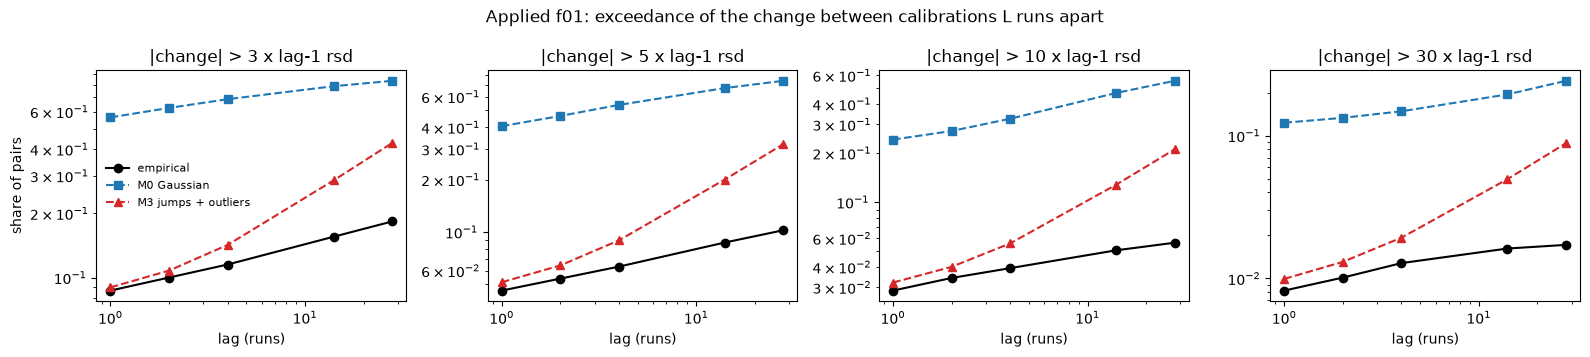

In [6]:
# Paths from the in-sample M0 and M3 fits on each qubit's own run times and segments
t0 = time.time()
sim = {m: jumps.simulate(jumps.natural(th[m]), data, N_SIM, rng) for m in ["M0", "M3"]}

# Flatten to paths x (qubit, row), and map each (qubit, run) to its flat position
n_cols = data["Y"].shape[1]
flat = {m: s.transpose(1, 0, 2).reshape(N_SIM, -1) for m, s in sim.items()}
ii, kk = np.nonzero(data["index"] >= 0)
row_id = data["index"][ii, kk]
run_key = pd.MultiIndex.from_arrays([clean.loc[row_id, "qubit"], clean.loc[row_id, "run"]])
pos = pd.Series(ii * n_cols + kk, index=run_key)
print(f"simulation time {time.time() - t0:.0f} s")

tail_rows = []
for L in LAGS:
    # Pairs of clean rows L runs apart in one segment, and where they sit in the paths
    p = methods.lag_pairs(clean, ["qubit", "seg"], L, col="y", cuts=CUTS)
    f0 = pos.reindex(pd.MultiIndex.from_arrays([p["qubit"], p["run_0"]])).to_numpy()
    f1 = pos.reindex(pd.MultiIndex.from_arrays([p["qubit"], p["run_0"] + L])).to_numpy()
    span_days = (p["t_1"] - p["t_0"]) / pd.Timedelta("1D")

    # Changes in units of the qubit's lag-1 robust sd: the data, then each model's paths
    scale = s1.loc[p["qubit"]].to_numpy()
    z_emp = np.abs(p["d"].to_numpy()) / scale
    z_mod = {m: np.abs(flat[m][:, f1] - flat[m][:, f0]) / scale for m in sim}

    # Share of pairs beyond each threshold
    for K in K_TAIL:
        row = {
            "lag": L,
            "K": K,
            "pairs": len(p),
            "median_days": np.median(span_days),
            "empirical": np.mean(z_emp > K),
        }
        row |= {m: np.mean(z_mod[m] > K) for m in sim}
        tail_rows.append(row)

tail_tab = pd.DataFrame(tail_rows).set_index(["lag", "K"])
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tail_tab)

# One panel per threshold: the share against lag, for the data and both models
fig, axes = plt.subplots(1, len(K_TAIL), figsize=(4 * len(K_TAIL), 3.6), sharex=True)
for ax, K in zip(axes, K_TAIL):
    t = tail_tab.xs(K, level="K")
    ax.plot(t.index, t["empirical"], "ko-", label="empirical")
    ax.plot(t.index, t["M0"], "C0s--", label="M0 Gaussian")
    ax.plot(t.index, t["M3"], "C3^--", label="M3 jumps + outliers")
    ax.set(
        xscale="log",
        yscale="log",
        xlabel="lag (runs)",
        title=f"|change| > {K} x lag-1 rsd",
    )
axes[0].set_ylabel("share of pairs")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Applied f01: exceedance of the change between calibrations L runs apart")
fig.tight_layout()
fig.savefig(FIG / "d2b_tails.png", dpi=130)
plt.show()

**Results.**

- At lag 1 (median 0.502 days), the share above 3 robust sd is 0.087 in the data, 0.564 under M0 and 0.09 under M3.
- At lag 28 (14 days), above 3: data 0.183, M0 0.836, M3 0.427. Above 30: 0.0172, 0.242 and 0.0885.
- M3's share is above the data's at every lag and $K$ in the table, and the excess grows with the lag.


## 6. Jumps and outliers, run by run

The M3 fit gives each run its lag-1 posterior probabilities (section 2):

$$p_J = P(\text{jump}_t \mid y_{\le t+1}), \qquad p_O = P(\text{outlier}_t \mid y_{\le t+1}).$$

A run is a **jump** when $p_J > 0.5$ (P_CLASS) and $p_J \ge p_O$, an **outlier** when $p_O > 0.5$ and $p_O > p_J$, and otherwise **quiet**. A jump should stay and an outlier should go back, so we compare the change into each run with the change out of it. We also compare the share of `warned` runs, since a failed step could cause an outlier. The figure shows the qubit with the most labelled jumps.


,runs,qubits,warned,median_abs_d_in,median_abs_d_out,reverts
label,,,,,,
first in segment,478,30,0.0523,NaN,5.61,NaN
jump,1049,30,0.141,32,5.9,0.0308
outlier,2887,30,0.232,24.7,26.4,0.84
quiet,32624,30,0.0267,4.07,4.17,0.458


labelled runs per qubit (median, max): {'jump': (34, 69), 'outlier': (91, 280)}
labelled jumps per 30 days, median over qubits: 1.193 | M3 fitted rate (all three scales), median: 2.224


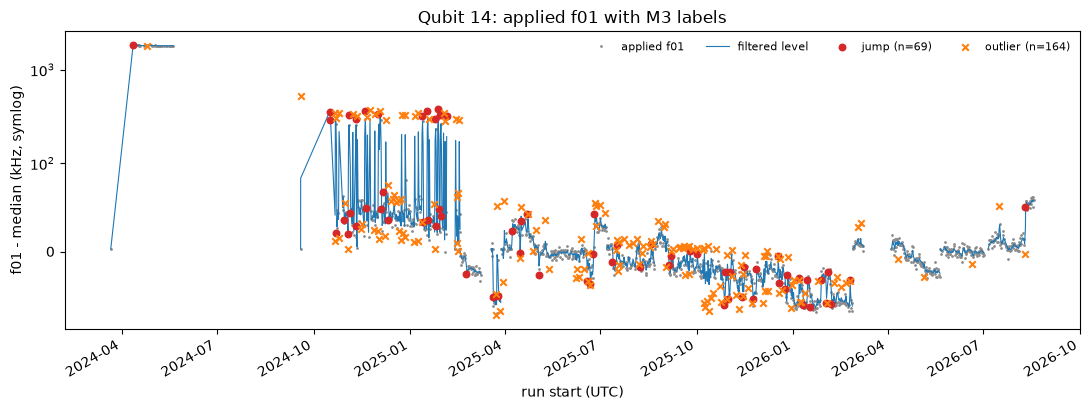

In [7]:
# Lag-1 probabilities, filtered level and PIT from the in-sample M3 fit, joined onto the rows
th3_col = {k: v[:, None] for k, v in th["M3"].items()}
_, rec3 = jumps.run_filter(th3_col, data, detail=True, lag1=True)
ok = data["index"] >= 0
lab = pd.DataFrame(
    {k: rec3[k][ok] for k in ["p_jump_s", "p_out_s", "level", "pit"]},
    index=data["index"][ok],
)
clean = clean.drop(columns=[c for c in lab.columns if c in clean.columns]).join(lab)

# Label by the larger posterior above P_CLASS; segment starts have no lag-1 posterior
is_jump = (clean["p_jump_s"] > P_CLASS) & (clean["p_jump_s"] >= clean["p_out_s"])
is_out = (clean["p_out_s"] > P_CLASS) & (clean["p_out_s"] > clean["p_jump_s"])
clean["label"] = np.select([is_jump, is_out], ["jump", "outlier"], "quiet")
clean.loc[clean["p_jump_s"].isna(), "label"] = "first in segment"

# Per label: runs, qubits, warned share, and the median change into and out of the run
cls = clean.groupby("label").agg(
    runs=("y", "size"),
    qubits=("qubit", "nunique"),
    warned=("warned", "mean"),
    median_abs_d_in=("d", lambda s: s.abs().median()),
    median_abs_d_out=("d_next", lambda s: s.abs().median()),
)

# Share of each label whose next change undoes at least half of this one
lab_rows = clean[clean["label"].isin(["jump", "outlier", "quiet"])].dropna(subset=["d", "d_next"])
flips = np.sign(lab_rows["d_next"]) != np.sign(lab_rows["d"])
rev = flips & (lab_rows["d_next"].abs() > 0.5 * lab_rows["d"].abs())
cls["reverts"] = rev.groupby(lab_rows["label"]).mean()
with pd.option_context("display.float_format", "{:.3g}".format):
    display(cls)

# Labelled runs per qubit
per_q = clean.pivot_table(index="qubit", columns="label", values="y", aggfunc="size", fill_value=0)
print(
    "labelled runs per qubit (median, max):",
    {c: (int(per_q[c].median()), int(per_q[c].max())) for c in ["jump", "outlier"] if c in per_q},
)

# Labelled jumps per 30 days against the fitted M3 rate
days = clean.groupby("qubit")["t"].agg(lambda t: (t.max() - t.min()) / pd.Timedelta("1D"))
labelled_rate = (per_q.get("jump", 0) / days * 30).median()
fitted_rate = par["M3"]["jumps_per_30d"].median()
print(
    "labelled jumps per 30 days, median over qubits:",
    round(float(labelled_rate), 3),
    "| M3 fitted rate (all three scales), median:",
    round(float(fitted_rate), 3),
)

# Example: the qubit with the most labelled jumps, relative to its median
qx = int(per_q["jump"].idxmax()) if "jump" in per_q else qubits[0]
g = clean[clean["qubit"] == qx]
fig, ax = plt.subplots(figsize=(11, 4.2))
base = g["y"].median()

# Applied values, and the filtered level drawn segment by segment
ax.plot(g["t"], g["y"] - base, ".", ms=2, color="0.55", label="applied f01")
for sg, h in g.groupby("seg"):
    ax.plot(
        h["t"],
        h["level"] - base,
        "-",
        lw=0.8,
        color="C0",
        label="filtered level" if sg == g["seg"].iloc[0] else None,
    )

# Labelled runs on top
for labl, st in [
    ("jump", {"color": "C3", "marker": "o", "s": 22}),
    ("outlier", {"color": "C1", "marker": "x", "s": 22}),
]:
    h = g[g["label"] == labl]
    ax.scatter(h["t"], h["y"] - base, label=f"{labl} (n={len(h)})", zorder=3, **st)

ax.set_yscale("symlog", linthresh=10 * s1.loc[qx])
ax.set(
    title=f"Qubit {qx}: applied f01 with M3 labels",
    xlabel="run start (UTC)",
    ylabel="f01 - median (kHz, symlog)",
)
ax.legend(frameon=False, fontsize=8, ncol=4)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG / "d2b_trajectory.png", dpi=130)
plt.show()

**Results.**

- 1,049 runs are jumps, 2,887 outliers and 32,624 quiet, and every label is on all 30 qubits. The warned share is 0.141 for jumps, 0.232 for outliers and 0.0267 for quiet runs.
- 0.0308 of jumps revert, against 0.84 of outliers. The median $\lvert\text{change}\rvert$ out of a jump is 5.9 kHz, close to a quiet run's 4.17 kHz.
- The median qubit has 1.193 labelled jumps per 30 days, against M3's fitted 2.224. So about half of the fitted jumps get no label.


## 7. Allan deviation

The Allan deviation asks: if we average f01 over $m$ consecutive runs, how much do two neighbouring averages differ? With $\bar y_j$ the mean of rows $j$ to $j+m-1$,

$$\sigma_A^2(m) = \tfrac{1}{2}\,\big\langle\,(\bar y_{j+m} - \bar y_j)^2\,\big\rangle .$$

Its slope on log-log axes shows the type of noise: $-1/2$ for white noise (averaging helps), $0$ for flicker ($1/f$) noise (averaging stops helping) and $+1/2$ for a random walk. Sections 3 to 5 don't test $1/f$ noise. Many weak defects together typically give $1/f$ frequency noise, so a flat part would point to them. The curve also shows whether the jumps add up like a random walk, as M3 assumes.

We compute it on four series and compare each with M3's prediction: the applied values, the same detrended per stretch, the applied values with outliers out, and with jumps and outliers out.

<details>
<summary><b>M3's prediction and the estimator</b></summary>

M3 is a white part $W$ (variance per run) plus a random walk $V$ (variance per day). With $\Delta$ days per row,

$$\sigma_A^2(m) = \frac{W}{m} + V\Delta\,\frac{2m^2+1}{6m}, \qquad W = R + \sum_k r_k\,(s_k O)^2, \qquad V = q + \sum_k \lambda_k\,(s_k J)^2 .$$

| Series | Taken out | M3 prediction uses |
|---|---|---|
| applied | nothing | $W$, $V$ |
| applied, detrended | a straight line per stretch | none |
| outliers out | rows labelled outlier in section 6 | $R$, $V$ |
| jumps and outliers out | also the filtered level change at each labelled jump, to the end of the segment | $R$, $q$ |

- **Stretches.** The clean rows of one qubit in one segment, split where two rows are more than STRETCH_GAP apart. $m$ counts rows, shown in days at the median spacing.
- **Estimator.** Overlapping, pooled over a qubit's stretches. A qubit enters at $m$ once it has ADEV_MIN_INDEP $\times\, m$ differences. It is a mean square, so heavy tails raise it.
- **Summary.** Per qubit, the ratio of data to M3 and the log-log slope to the next $m$, as medians over qubits with a 95% interval from resampling qubits.

</details>


In [8]:
def stretches(d: pd.DataFrame, col: str, detrend: bool = False) -> list[np.ndarray]:
    """Values of col in each unbroken stretch of one qubit.

    A stretch stays in one segment, with no two rows more than STRETCH_GAP apart.
    detrend takes a straight line out of each stretch.
    """
    new = d["seg"].ne(d["seg"].shift()) | d["t"].diff().gt(STRETCH_GAP)
    out = []
    for _, g in d.groupby(new.cumsum().to_numpy()):
        y = g[col].to_numpy(float)
        if detrend and len(y) >= 3:
            x = np.arange(len(y))
            y = y - np.polyval(np.polyfit(x, y, 1), x)
        out.append(y)
    return out


def avar(segs: list[np.ndarray], m: int) -> tuple[float, int]:
    """Overlapping Allan variance at m rows, pooled over stretches, and the differences behind it."""
    ss, n = 0.0, 0
    for y in segs:
        if len(y) < 2 * m:
            continue

        # Means of rows j to j+m-1 from a running sum, then neighbouring differences
        c = np.concatenate([[0.0], np.cumsum(y)])
        mean_m = (c[m:] - c[:-m]) / m
        dd = mean_m[m:] - mean_m[:-m]
        ss += (dd**2).sum() / 2
        n += len(dd)
    return (ss / n if n else np.nan), n


def m3_avar(white, walk, dt, m):
    """Allan variance of white noise (variance per row) plus a random walk (variance per day).

    dt is days per row.
    """
    return white / m + walk * dt * (2 * m**2 + 1) / (6 * m)


# The four series: jump steps are the filtered level change at runs labelled jump (section 6)
a = clean.sort_values(["qubit", "seg", "t"]).copy()
by_seg = a.groupby(["qubit", "seg"])
a["step"] = by_seg["level"].diff().where(a["label"] == "jump", 0.0).fillna(0.0)
a["y_dj"] = a["y"] - a.groupby(["qubit", "seg"])["step"].cumsum()
kept = a[a["label"] != "outlier"]
SERIES = {
    "applied": (a, "y", False),
    "applied, detrended": (a, "y", True),
    "outliers out": (kept, "y", False),
    "jumps and outliers out": (kept, "y_dj", False),
}

# Days per row: the median spacing inside stretches, per qubit
gap = by_seg["t"].diff()
dt_days = (gap[gap <= STRETCH_GAP] / pd.Timedelta("1D")).groupby(a["qubit"]).median()

# Stretch lengths over all qubits
seg_len = pd.Series([len(y) for q, g in a.groupby("qubit") for y in stretches(g, "y")])
print(
    f"stretches {len(seg_len)}: median {seg_len.median():.0f} rows, "
    f"90th percentile {seg_len.quantile(0.9):.0f}, longest {seg_len.max()}; "
    f"median spacing {dt_days.median():.3g} days per row"
)

# M3 white and walk parts per qubit (kHz^2): outliers add to the white part, jumps to the walk
nat = jumps.natural(th["M3"])
white = nat["R"] + sum(nat[n] * (s * nat["O"]) ** 2 for n, s in zip(jumps.RK, jumps.SCALES))
walk = nat["q"] + sum(nat[n] * (s * nat["J"]) ** 2 for n, s in zip(jumps.LAM, jumps.SCALES))
mod = pd.DataFrame(
    {"R": nat["R"], "q": nat["q"], "white": white, "walk": walk},
    index=qubits,
).join(dt_days.rename("dt"))

# Which M3 parts each series is compared with (the detrended one has no prediction)
REF = {
    "applied": ("white", "walk"),
    "outliers out": ("R", "walk"),
    "jumps and outliers out": ("R", "q"),
}

# Allan deviation per series, qubit and m, with the matching M3 prediction
recs = []
for q, g in a.groupby("qubit"):
    for name, (d, col, dtr) in SERIES.items():
        segs = stretches(d[d["qubit"] == q], col, dtr)
        for m in ADEV_M:
            v, n = avar(segs, m)

            # Skip m where the qubit has too few differences
            if n < ADEV_MIN_INDEP * m:
                continue

            if name in REF:
                white_q, walk_q = mod.loc[q, list(REF[name])]
                ref = np.sqrt(m3_avar(white_q, walk_q, mod.loc[q, "dt"], m))
            else:
                ref = np.nan

            recs.append(
                {
                    "series": name,
                    "qubit": q,
                    "m": m,
                    "adev_kHz": np.sqrt(v),
                    "m3_kHz": ref,
                }
            )
ad = pd.DataFrame(recs)
ad["ratio"] = ad["adev_kHz"] / ad["m3_kHz"]

# Log-log slope from each m to the next one of the same series and qubit
ad = ad.sort_values(["series", "qubit", "m"])
nxt = ad.groupby(["series", "qubit"])
d_log_adev = np.log(nxt["adev_kHz"].shift(-1) / ad["adev_kHz"])
d_log_m = np.log(nxt["m"].shift(-1) / ad["m"])
ad["slope"] = d_log_adev / d_log_m


def med_ci(v) -> tuple[float, float, float]:
    """Median over qubits with a 95% interval from resampling qubits."""
    v = np.asarray(v, float)
    v = v[np.isfinite(v)]
    if len(v) < 3:
        return np.nan, np.nan, np.nan
    boot = np.median(rng.choice(v, (N_BOOT, len(v))), axis=1)
    return float(np.median(v)), *np.percentile(boot, [2.5, 97.5])


# Medians over qubits per series and m, with intervals on the ratio and the slope
rows_ad = []
for (name, m), g in ad.groupby(["series", "m"], sort=False):
    r, s = med_ci(g["ratio"]), med_ci(g["slope"])
    rows_ad.append(
        {
            "series": name,
            "m": m,
            "days": m * dt_days.median(),
            "qubits": len(g),
            "adev_kHz": g["adev_kHz"].median(),
            "m3_kHz": g["m3_kHz"].median(),
            "ratio": r[0],
            "ratio_lo": r[1],
            "ratio_hi": r[2],
            "slope_to_next": s[0],
            "slope_lo": s[1],
            "slope_hi": s[2],
        }
    )
adev_tab = pd.DataFrame(rows_ad).set_index(["series", "m"]).loc[list(SERIES)]
with pd.option_context("display.float_format", "{:.3g}".format):
    display(adev_tab)

# Where each median curve bottoms out (only m with at least half the qubits)
full = adev_tab[adev_tab["qubits"] >= len(qubits) / 2]
low = full.groupby(level="series", sort=False)["adev_kHz"].idxmin()
last = full.reset_index("m").groupby(level="series", sort=False)["m"].max()
lowest = {}
for name, i in low.items():
    at_last = " (the last m)" if i[1] == last[name] else ""
    lowest[name] = (
        f"m {i[1]} ({full.loc[i, 'days']:.3g} days): {full.loc[i, 'adev_kHz']:.3g} kHz" + at_last
    )
print("minimum of the median curve:", lowest)

stretches 870: median 10 rows, 90th percentile 145, longest 345; median spacing 0.505 days per row


days  qubits  adev_kHz  m3_kHz  ratio  ratio_lo  ratio_hi  slope_to_next  slope_lo  slope_hi
series                 m                                                                                               
applied                1  0.505      30      33.4    52.9  0.627     0.569     0.707         -0.244    -0.324   -0.0951
                       2   1.01      30      27.1    55.5  0.571      0.46     0.667         -0.146      -0.3    -0.041
                       4   2.02      30      22.8    68.1  0.398     0.294     0.484        -0.0819    -0.392   -0.0155
                       8   4.04      30      16.9    92.9  0.249     0.134     0.308          -0.18    -0.352    0.0269
                       16  8.08      30      13.6     130  0.128    0.0733      0.21         -0.173    -0.279   -0.0466
                       32  16.2      30        11     184 0.0763    0.0455     0.113            NaN       NaN       NaN
applied, detrended     1  0.505      30      33.2     NaN    NaN       NaN       NaN         -0.264    -0.354    -0.115
                       2   1.01      30      27.1     NaN    NaN       NaN       NaN         -0.191     -0.35   -0.0626
                       4   2.02      30      22.6     NaN    NaN       NaN       NaN          -0.11    -0.332   -0.0201
                       8   4.04      30      16.8     NaN    NaN       NaN       NaN         -0.214    -0.353   -0.0135
                       16  8.08      30      11.6     NaN    NaN       NaN       NaN         -0.264    -0.465    -0.123
                       32  16.2      30      8.81     NaN    NaN       NaN       NaN            NaN       NaN       NaN
outliers out           1  0.505      30      16.3    39.9  0.577     0.397     0.771         0.0183    -0.102     0.122
                       2   1.01      30      15.4    48.7  0.457     0.349      0.61         -0.168    -0.248  -0.00113
                       4   2.02      30      13.8    65.9   0.34     0.214     0.406         -0.169    -0.366   -0.0645
                       8   4.04      30      10.5    92.1  0.177    0.0912     0.245        -0.0854     -0.42     0.136
                       16  8.08      30       7.3     130 0.0788    0.0599     0.134         -0.188    -0.252   -0.0982
                       32  16.2      28      6.44     184  0.048    0.0303    0.0835            NaN       NaN       NaN
jumps and outliers out 1  0.505      30      7.92    3.74   1.63      1.25      2.82         -0.174     -0.26   -0.0244
                       2   1.01      30      7.28    2.65   1.82      1.51      3.61          -0.12    -0.212   0.00836
                       4   2.02      30      6.61    1.92   2.31      1.92      4.61         -0.106    -0.211   -0.0164
                       8   4.04      30      5.35    1.39   3.09      2.55      5.32        0.00482    -0.195     0.204
                       16  8.08      30       4.9    1.03   3.98      3.13      4.55        -0.0262    -0.172     0.268
                       32  16.2      28      4.83   0.697   4.75      3.47      7.87            NaN       NaN       NaN

minimum of the median curve: {'applied': 'm 32 (16.2 days): 11 kHz (the last m)', 'applied, detrended': 'm 32 (16.2 days): 8.81 kHz (the last m)', 'outliers out': 'm 32 (16.2 days): 6.44 kHz (the last m)', 'jumps and outliers out': 'm 32 (16.2 days): 4.83 kHz (the last m)'}


/tmp/ipykernel_15046/1634033458.py:15: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "o-" (-> linestyle='-'). The keyword argument will take precedence.
  axs[0].plot(t.index * DT, t["adev_kHz"], "o-", ms=4, label=name, **STYLE[name])


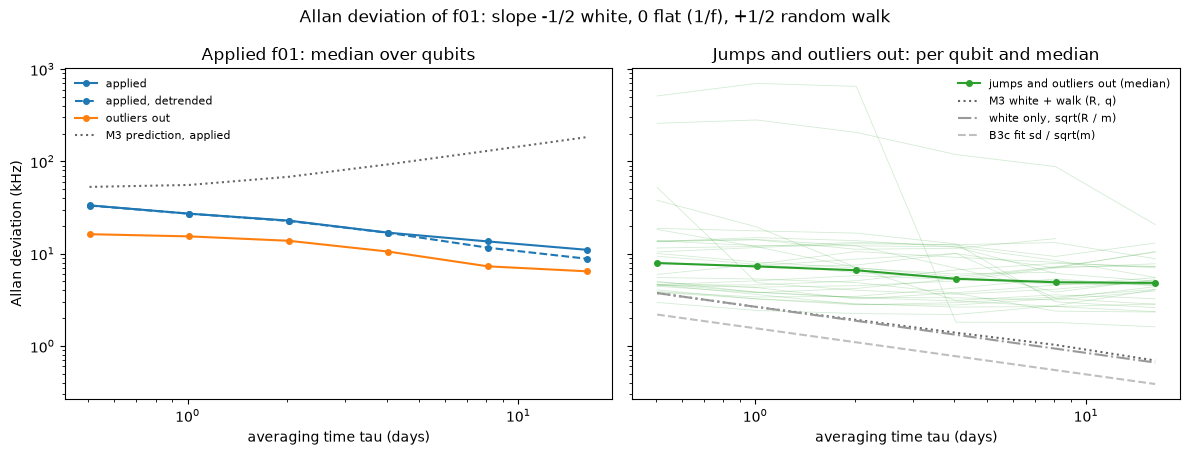

In [9]:
# One style per series, and days per row to put m on a time axis
STYLE = {
    "applied": {"color": "C0"},
    "applied, detrended": {"color": "C0", "ls": "--"},
    "outliers out": {"color": "C1"},
    "jumps and outliers out": {"color": "C2"},
}
DT = dt_days.median()  # days per row

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)

# Left: the applied series three ways, with M3's prediction for the applied one
for name in ["applied", "applied, detrended", "outliers out"]:
    t = adev_tab.loc[name]
    axs[0].plot(t.index * DT, t["adev_kHz"], "o-", ms=4, label=name, **STYLE[name])
t = adev_tab.loc["applied"]
axs[0].plot(t.index * DT, t["m3_kHz"], ":", color="0.4", label="M3 prediction, applied")
axs[0].set(title="Applied f01: median over qubits")

# Right: jumps and outliers out, faint per qubit and the median, against M3's R and q
name = "jumps and outliers out"
for q, g in ad[ad["series"] == name].groupby("qubit"):
    axs[1].plot(g["m"] * DT, g["adev_kHz"], "-", lw=0.6, color="C2", alpha=0.2)
t = adev_tab.loc[name]
axs[1].plot(t.index * DT, t["adev_kHz"], "o-", ms=4, label=f"{name} (median)", **STYLE[name])
axs[1].plot(t.index * DT, t["m3_kHz"], ":", color="0.4", label="M3 white + walk (R, q)")

# Reference lines: M3's white part alone, and the B3c fit sd averaged down
m_ = np.asarray(t.index)
axs[1].plot(
    m_ * DT,
    np.sqrt(mod["R"].median() / m_),
    "-.",
    color="0.6",
    label="white only, sqrt(R / m)",
)
axs[1].plot(m_ * DT, sig3c.median() / np.sqrt(m_), "--", color="0.75", label="B3c fit sd / sqrt(m)")
axs[1].set(title="Jumps and outliers out: per qubit and median")

for ax in axs:
    ax.set(xscale="log", yscale="log", xlabel="averaging time tau (days)")
    ax.legend(frameon=False, fontsize=8)
axs[0].set_ylabel("Allan deviation (kHz)")
fig.suptitle("Allan deviation of f01: slope -1/2 white, 0 flat (1/f), +1/2 random walk")
fig.tight_layout()
fig.savefig(FIG / "d2b_allan.png", dpi=130)
plt.show()

**Results.**

- The median spacing is 0.505 days per row, so $m = 32$ is 16.2 days. The applied series falls from 33.4 kHz at $m = 1$ to 11 kHz at 16.2 days, and every series is lowest at the last $m$.
- M3 predicts a rise from 52.9 to 184 kHz over the same range. The ratio of data to M3 falls from 0.627 [0.569, 0.707] to 0.0763 [0.0455, 0.113].
- With jumps and outliers out, the curve is flat from 4 days on at about 5 kHz (slope 0.00482 [−0.195, 0.204] from 4 to 8 days). Small jumps that got no label in section 6 would also give a flat part.


## Part 2. Extensions and the setpoint

Part 1 leaves two open points: M3 predicts too many large moves at two weeks (section 5), and we haven't tested its level as a setpoint.

M3 leaves out three things. A run's noise may depend on which FineFrequency step it ended on, a jump may partly decay, and the parameters may change over two years. We add the first two to the model (M3s, M4 and M4s) and test the third with rolling and walk-forward fits. Then we replay the setpoint rules. The set-up cell below reloads what Part 2 needs, so Part 2 also runs on its own.


In [10]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import jumps, methods, series
from qpu_drift.analysis.constants import FINE_LADDER_05, FINE_LADDER_05_OFF, MIN_N
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results
from qpu_drift.paths import REPO_ROOT

pd.set_option(
    "display.max_rows",
    200,
    "display.max_columns",
    30,
    "display.width",
    250,
    "display.max_colwidth",
    120,
)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

# All seven models, and M3 with its three extensions
MODELS = list(jumps.MODELS)
EXTENDED = ["M3", "M3s", "M4", "M4s"]
NAMES = {
    "M0": "Gaussian",
    "M1": "jumps",
    "M2": "outliers",
    "M3": "jumps + outliers",
    "M3s": "M3 + stage noise",
    "M4": "M3 + pull-back",
    "M4s": "M3 + stage noise + pull-back",
}

# Test rows before and after this date are also scored apart (section 11)
CYCLE_START = periods.THERMAL_CYCLES[0][0]

# Change over L runs (section 12)
LAGS = [1, 2, 4, 14, 28]  # runs: half a day to two weeks
K_TAIL = [3, 5, 10, 30]  # exceedance thresholds in units of the qubit's lag-1 robust sd
N_SIM = 100  # simulated paths per qubit

# Parameters over time (section 13): the model refitted, rolling windows and walk-forward blocks
ROLL_MODEL = "M4s"
WINDOW, STEP = pd.Timedelta("120D"), pd.Timedelta("60D")  # rolling fits
BLOCK, ROLL = pd.Timedelta("60D"), pd.Timedelta("240D")  # test blocks, rolling training span
WARM_CYCLES, WARM_SPAN = 5, 1.0  # coordinate search from a fitted start
MIN_STAGE_ROWS = 10  # rows of a stage a window needs before its noise ratio is shown

# Setpoint replay (section 14)
MAX_GAP_DAYS = 1.5  # longest interval replayed
HYBRID_KHZ = [20, 50]  # hybrid rule thresholds
CORE_KHZ = 30  # core intervals: every rule within this of the next measurement

# Stateless rule grid (section 14): no move below the deadband, a share GAIN of the change up to
# RESET_KHZ, and the full measurement at or above it
DEADBAND_KHZ = [0, 5, 10, 15]
GAIN = [0.1, 0.25, 0.5, 0.75, 1.0]
RESET_KHZ = 50

# Per-window check (section 15): lags in runs, thresholds in lag-1 robust sd
WIN_LAGS, WIN_K = [1, 14, 28], [3, 30]

# Where the filter restarts: incident starts and untracked DS2 writes that touched calibrate_1q
INCIDENT_STARTS = [i.period[0] for i in periods.INCIDENTS]
U1 = [u.at for u in periods.UNTRACKED_DS2 if "calibrate_1q" in u.routines]
CUTS = INCIDENT_STARTS + U1

rng = np.random.default_rng(0)

## 8. Series and the FineFrequency stage

We join each run's FineFrequency stage to the section 1 series. calibrate_1q adds a freq result id only for a step that passes its range check, and stops at the first failure. So the number of freq ids shows how far the run got (`series.fine_freq_stage`).

- **Stage 0** is the full ladder: three steps from FINE_LADDER_05, and two steps before it and inside FINE_LADDER_05_OFF.
- **Stage 1** is one step short.
- **Stage 2** is two or more short, so the 0.1 µs step or the Ramsey value was applied.

We use the stage and not the last delay, because a failed step marks a run where the qubit was far from the value that step expected. A full run on the 2-step ladder changes about as little as one on the 3-step ladder.

<details>
<summary><b>Checks</b></summary>

- **Ladder dates.** From FINE_LADDER_05 on, every run where no qubit reaches three accepted steps should be inside FINE_LADDER_05_OFF (2025-03-20 to 2025-03-28, when the old calibrate_1q code was back).
- **No result ids.** A few early runs have none. They get the full ladder of their time, and their `warned` flag is false.
- **Tables.** The size of the change by ladder and accepted steps, by stage, and the stage mix per stratum.

</details>


In [11]:
# The applied f01 of every calibrate_1q run, one row per qubit and run
runs1q = load_run_map(routine="calibrate_1q")
rows = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)
keep_cols = ["qubit", "run", "t", "value", "warned", "incident", "f01_flag", "stratum"]
f = rows.loc[rows["param"] == "freq", keep_cols]
f = f.rename(columns={"value": "y_hz"}).sort_values(["qubit", "run"], ignore_index=True)
f["settling"] = f["stratum"] == "settling"

# Segment: the stratum, split by the number of cuts before the row
cuts_sorted = np.sort(np.array(CUTS, dtype="datetime64[ns]"))
cut_no = np.searchsorted(cuts_sorted, f["t"].to_numpy("datetime64[ns]"), side="left")
f["seg"] = f["stratum"] + " c" + pd.Series(cut_no).astype(str)

# The B3c fit sd of freq per qubit and stratum, for comparison
sig = series.ds1_1q_noise(load_noise_floor()).xs("freq", level="param")["sigma"].rename("sigma")
f = f.join(sig, on=["qubit", "stratum"])

# Clean rows (no incident, f01 flag or settling), on qubits with at least MIN_N of them
clean = f[~(f["incident"] | f["f01_flag"] | f["settling"])].copy()
n_q = clean.groupby("qubit").size()
clean = clean[clean["qubit"].isin(n_q[n_q >= MIN_N].index)].sort_values(
    ["qubit", "t"], ignore_index=True
)
clean["warned"] = clean["warned"].astype("boolean").fillna(False).astype(bool)

# f01 in kHz from the segment's first value, and the change into each run
first = clean.groupby(["qubit", "seg"])["y_hz"].transform("first")
clean["y"] = (clean["y_hz"] - first) / 1e3
clean["d"] = clean.groupby(["qubit", "seg"])["y"].diff()

# The FineFrequency stage per run and qubit, and the most accepted steps any qubit reached per run
stage = series.fine_freq_stage(load_run_results()).rename(columns={"start": "t"})
run_max = stage.groupby("t")["n_freq"].max()

# Ladder check: runs from FINE_LADDER_05 on with no qubit at 3 steps, and how many sit in the gap
late = run_max[run_max.index >= FINE_LADDER_05]
off = periods.within(late.index, FINE_LADDER_05_OFF)
n_short = int((late < 3).sum())
n_short_off = int((late[off] < 3).sum())
off_first, off_last = late.index[off].min(), late.index[off].max()
print(
    f"runs from FINE_LADDER_05 ({FINE_LADDER_05}) with no qubit at 3 accepted steps: "
    f"{n_short} of {len(late)}; "
    f"inside FINE_LADDER_05_OFF ({FINE_LADDER_05_OFF[0]} to {FINE_LADDER_05_OFF[1]}): "
    f"{n_short_off} of {int(off.sum())} runs, "
    f"{off_first:%Y-%m-%d %H:%M} to {off_last:%Y-%m-%d %H:%M}"
)

# The nearest 3-step runs either side of the gap, and any 3-step run before FINE_LADDER_05
three = late == 3
before_off = late[(late.index < FINE_LADDER_05_OFF[0]) & three].index.max()
after_off = late[(late.index >= FINE_LADDER_05_OFF[1]) & three].index.min()
n_early_three = int((run_max[run_max.index < FINE_LADDER_05] >= 3).sum())
print(
    f"nearest runs with 3 steps: before {before_off:%Y-%m-%d %H:%M}, "
    f"after {after_off:%Y-%m-%d %H:%M}; "
    f"before FINE_LADDER_05, runs with a qubit at 3 steps: {n_early_three}"
)

# Join the stage onto the rows; rows with no result ids get the full ladder (stage 0)
clean = clean.merge(stage, on=["t", "qubit"], how="left", validate="one_to_one")
no_ids = clean["stage"].isna()
clean["stage"] = clean["stage"].fillna(0).astype(int)

t_first, t_last = clean["t"].min(), clean["t"].max()
print(
    f"clean rows {len(clean)}, qubits {clean['qubit'].nunique()}, "
    f"segments {clean['seg'].nunique()}, "
    f"{t_first:%Y-%m-%d} to {t_last:%Y-%m-%d}"
)
print(
    f"rows with no result ids (given the full ladder): {int(no_ids.sum())}, "
    f"warned {int(clean.loc[no_ids, 'warned'].sum())}"
)


def absd(q):
    """Aggregator: the q quantile of the absolute change."""
    return lambda s: s.abs().quantile(q)


# Per group: rows, qubits, warned share, and the size of the change
stats = {
    "rows": ("y", "size"),
    "qubits": ("qubit", "nunique"),
    "warned": ("warned", "mean"),
    "median_abs_d_kHz": ("d", absd(0.5)),
    "p90_abs_d_kHz": ("d", absd(0.9)),
    "p99_abs_d_kHz": ("d", absd(0.99)),
}

# By ladder and accepted steps: 3 steps from FINE_LADDER_05, except inside FINE_LADDER_05_OFF
on_3_step = (clean["t"] >= FINE_LADDER_05) & ~periods.within(clean["t"], FINE_LADDER_05_OFF)
era = np.where(on_3_step, "3-step ladder", "2-step ladder")
print(
    "by ladder (3 steps from FINE_LADDER_05 outside FINE_LADDER_05_OFF) "
    "and accepted FineFrequency steps:"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(clean.groupby([era, "n_freq"]).agg(**stats))

# By stage
by_stage = clean.groupby("stage").agg(**stats)
by_stage.index = [jumps.STAGES[i] for i in by_stage.index]
print("by stage:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(by_stage)

# Stage mix per stratum, strata in number order
stage_name = clean["stage"].map(dict(enumerate(jumps.STAGES)))
mix = pd.crosstab(clean["stratum"], stage_name)
display(mix.sort_index(key=lambda i: i.str.split().str[0].astype(int)))

runs from FINE_LADDER_05 (2025-02-17 16:11:02) with no qubit at 3 accepted steps: 18 of 1025; inside FINE_LADDER_05_OFF (2025-03-20 12:00:58 to 2025-03-28 19:44:15): 18 of 18 runs, 2025-03-20 12:00 to 2025-03-28 08:45
nearest runs with 3 steps: before 2025-03-20 08:00, after 2025-03-28 19:44; before FINE_LADDER_05, runs with a qubit at 3 steps: 0
clean rows 37038, qubits 30, segments 16, 2024-03-21 to 2026-08-18
rows with no result ids (given the full ladder): 145, warned 0
by ladder (3 steps from FINE_LADDER_05 outside FINE_LADDER_05_OFF) and accepted FineFrequency steps:


rows  qubits  warned  median_abs_d_kHz  p90_abs_d_kHz  p99_abs_d_kHz
              n_freq                                                                       
2-step ladder 0          74       7   0.946              16.1            443       1.27e+04
              1         194      10       1               101            294       2.71e+03
              2        7469      30       0              5.89           18.4            167
3-step ladder 0         797      21   0.981              21.2            103        1.4e+03
              1         592      17       1              83.3            304          1e+03
              2         102      24   0.765              71.2            283       3.52e+03
              3       27665      30       0              4.12           19.5            117

by stage:


,rows,qubits,warned,median_abs_d_kHz,p90_abs_d_kHz,p99_abs_d_kHz
full ladder,35279,30,0,4.45,19.3,138
1 step short,296,25,0.919,82,293,3.58e+03
2+ short,1463,25,0.987,33.9,255,2e+03


stage,1 step short,2+ short,full ladder
stratum,,,
0 (start),33,6,891
2 (2024-09-18),141,11,5909
3 (2025-02-12),5,19,335
4 (2025-02-17),2,39,1069
5 (2025-03-18),0,1,89
6 (2025-03-20),15,38,479
7 (2025-03-28),6,252,5496
8 (2025-07-07),5,103,2650
9 (2025-08-22),22,447,11256


**Results.**

- The ladder dates match the run map. All 18 runs from FINE_LADDER_05 with no qubit at three steps are inside FINE_LADDER_05_OFF. 145 rows have no result ids, and none is warned.
- **By stage.** The full ladder has 35,279 rows, a median $\lvert\text{change}\rvert$ of 4.45 kHz and none warned. One step short has 296 rows, a median of 82 kHz and 0.919 warned. Two or more short has 1,463 rows, a median of 33.9 kHz and 0.987 warned.
- Full runs change by a median 5.89 kHz on the 2-step ladder and 4.12 kHz on the 3-step ladder. Runs that stop at 2 steps on the 3-step ladder change by 71.2 kHz.


## 9. The producer's rule and the extended model

**The producer's rule.** Each calibrate_1q run fits a Ramsey and sets f01 to the fitted value. FineFrequency then refines it with delays of 0.1, 0.25 and 0.5 µs. A step with delay $T$ searches a range of $1/(10\,T)$ and is accepted only when its correction is inside half that range. At the first failure the run warns, and the last accepted value is applied. So the rule has gain one and no memory: each run replaces the old value with the new measurement.

**The extended model.** The level is now a baseline $b_t$ plus a deviation $x_t$. The baseline takes the random-walk step $w_t$ of section 2. The deviation decays by $a = e^{-\Delta t/\tau}$ between runs. A jump $j_t$ is split between the two:

$$b_t = b_{t-1} + w_t + (1 - w)\,j_t, \qquad x_t = a\,x_{t-1} + w\,j_t.$$

The applied value adds stage-dependent noise and the outlier of section 2:

$$y_t = b_t + x_t + e_t + o_t, \qquad \operatorname{Var} e_t = R,\ m_1 R \text{ or } m_2 R \text{ at stage 0, 1 or 2}.$$

<details>
<summary><b>Segment starts, filter and fits</b></summary>

**Segment starts.** At the first row of a segment, $b$ is unknown and $x$ has its long-run variance

$$P_x = w^2\,\frac{\tau}{2}\sum_k \lambda_k\,(s_k J)^2.$$

So the first row gives $b = y$ and $x = 0$, with variance of $b$ equal to the row's noise variance plus $P_x$, variance of $x$ equal to $P_x$, and covariance $-P_x$. The simulation starts each segment's $x$ from the same spread.

- **Filter.** The GPB1 filter of section 2 with a two-dimensional state. The filtered level is $b_t + x_t$.
- **Fits.** The coordinate search of section 2 (logit for $r_k$ and $w$). M3s starts from M3 with $\sqrt{m_1} = 2$ and $\sqrt{m_2} = 10$. M4 starts from M3 with $\tau = 10$ days and $w = 0.2$. M4s starts from M3s plus M4's $\tau$ and $w$.
- **Simulation.** `jumps.simulate` also draws each run's stage noise and the pull-back.

</details>


In [12]:
def fit_all(data: dict, s1: np.ndarray) -> tuple[dict, dict]:
    """Fit all seven models; s1 is each qubit's lag-1 robust sd (kHz).

    Each model starts from the fits it extends (section 9).
    """
    one = np.ones_like(s1)
    th, ll = {}, {}

    # M0 from the lag-1 robust sd
    start0 = {"R": np.log(s1 / np.sqrt(2) * 0.9), "q": np.log(0.3 * s1)}
    th["M0"], ll["M0"] = jumps.fit(data, "M0", start0)

    # M1: M0 plus jumps at 0.01 per day per scale, with J at 3 s1
    lam0 = {n: np.log(0.01) * one for n in jumps.LAM}
    th["M1"], ll["M1"] = jumps.fit(data, "M1", th["M0"] | lam0 | {"J": np.log(3 * s1)})

    # M2: M0 plus outliers at logit -5.3 (about 0.005 per run) per scale, with O at 3 s1
    r0 = {n: -5.3 * one for n in jumps.RK}
    th["M2"], ll["M2"] = jumps.fit(data, "M2", th["M0"] | r0 | {"O": np.log(3 * s1)})

    # M3: M1's fit plus M2's outlier parameters
    outliers = {n: th["M2"][n] for n in (*jumps.RK, "O")}
    th["M3"], ll["M3"] = jumps.fit(data, "M3", th["M1"] | outliers)

    # M3s: M3 plus stage noise sd ratios 2 and 10 (log units)
    stage0 = {"s1": np.log(2.0) * one, "s2": np.log(10.0) * one}
    th["M3s"], ll["M3s"] = jumps.fit(data, "M3s", th["M3"] | stage0)

    # M4: M3 plus a pull-back with tau 10 days and w 0.2 (logit)
    revert0 = {"tau": np.log(10.0) * one, "w": np.log(0.2 / 0.8) * one}
    th["M4"], ll["M4"] = jumps.fit(data, "M4", th["M3"] | revert0)

    # M4s: M3s plus M4's pull-back
    revert4 = {n: th["M4"][n] for n in jumps.REVERT}
    th["M4s"], ll["M4s"] = jumps.fit(data, "M4s", th["M3s"] | revert4)

    return th, ll


def params(th_m: dict, index) -> pd.DataFrame:
    """One model's parameters per qubit, in natural units.

    sds in kHz, jumps per 30 days, outliers per 100 runs, stage noise sd as a multiple of
    sqrt R, and the pull-back's tau (days) and w.
    """
    nat = jumps.natural(th_m)
    out = {"sqrt_R_kHz": np.sqrt(nat["R"]), "sqrt_q_kHz_per_sqrt_day": np.sqrt(nat["q"])}

    if "J" in nat:
        out["J_kHz"] = nat["J"]
        out["jumps_per_30d"] = 30 * sum(nat[n] for n in jumps.LAM)

    if "O" in nat:
        out["O_kHz"] = nat["O"]
        out["outliers_per_100_runs"] = 100 * sum(nat[n] for n in jumps.RK)

    if "m1" in nat:
        out["sd_x_1short"] = np.sqrt(nat["m1"])
        out["sd_x_2short"] = np.sqrt(nat["m2"])

    if "tau" in nat:
        out["tau_days"] = nat["tau"]
        out["w"] = nat["w"]

    return pd.DataFrame(out, index=index)


def as_col(th_m: dict) -> dict:
    """Parameters as (qubits, 1) columns: one candidate per qubit for run_filter."""
    return {k: v[:, None] for k, v in th_m.items()}

## 10. In-sample fit

We fit each model once per qubit on all clean rows, as in section 3.

- **Parameters.** $\sqrt{R}$ is the white noise on a full-ladder run. sd_x_1short and sd_x_2short are the noise sd of the other two stages as a multiple of $\sqrt{R}$, that is $\sqrt{m_1}$ and $\sqrt{m_2}$. $\tau$ and $w$ give how fast a jump decays and how much of it decays. A qubit with few rows of a stage keeps that ratio near its start value, so the per-qubit table also shows the rows per stage.
- **Comparison.** We take $\Delta\text{AIC}$ and $\Delta\text{BIC}$ against M3 per qubit, where a negative value favours the larger model. We also count the best model per qubit. $k$ is 2 plus the model's own parameters, and BIC uses the scored rows.

In [13]:
# Each qubit's lag-1 robust sd sets the starting values
s1 = clean.groupby("qubit")["d"].apply(lambda d: methods.rsd(d.to_numpy()))

# Fit all seven models on every clean row
data = jumps.panel(clean, np.ones(len(clean), bool))
qubits = data["qubits"]
t0 = time.time()
th, ll = fit_all(data, s1.loc[qubits].to_numpy())
print(f"fit time {time.time() - t0:.0f} s for {len(qubits)} qubits x {len(MODELS)} models")

# AIC and BIC per qubit and model
n_scored = data["SCORE"].sum(axis=1)
k_par = {m: 2 + len(p) for m, p in jumps.MODELS.items()}
aic = pd.DataFrame({m: 2 * k_par[m] - 2 * ll[m] for m in MODELS}, index=qubits)
bic = pd.DataFrame({m: k_par[m] * np.log(n_scored) - 2 * ll[m] for m in MODELS}, index=qubits)

# Medians over qubits, the gains over M3, and how often each model is best
par = {m: params(th[m], qubits) for m in MODELS}
summ = pd.DataFrame({m: par[m].median() for m in MODELS}).T
summ["dAIC_vs_M3_median"] = aic.sub(aic["M3"], axis=0).median()
summ["dBIC_vs_M3_median"] = bic.sub(bic["M3"], axis=0).median()
best_aic = aic.idxmin(axis=1).value_counts()
best_bic = bic.idxmin(axis=1).value_counts()
summ["best_by_AIC"] = best_aic.reindex(MODELS).fillna(0).astype(int)
summ["best_by_BIC"] = best_bic.reindex(MODELS).fillna(0).astype(int)
print(f"medians over {len(qubits)} qubits; scored rows {int(n_scored.sum())}")
with pd.option_context("display.float_format", "{:.4g}".format):
    display(summ)

# Rows of each stage per qubit
n_stage = (
    clean.groupby(["qubit", "stage"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=qubits, columns=[0, 1, 2], fill_value=0)
)
n_stage.columns = [f"rows_{s}" for s in jumps.STAGES]

# Under M4s: qubits whose jumps last (small w) or decay (large w), and tau stuck at a bound
w4 = par["M4s"]["w"]
n_last = int((w4 < 0.05).sum())
n_decay = int((w4 > 0.5).sum())
n_tau_bound = int(np.isin(th["M4s"]["tau"], jumps.BOUNDS["tau"]).sum())
print(
    f"M4s: qubits with w < 0.05 (jumps last, as in M3): {n_last}, w > 0.5: {n_decay}; "
    f"tau at a bound: {n_tau_bound}"
)

# M4s per qubit, with the stage counts and each extension's AIC gain over M3
d_aic = {f"dAIC_{m}_vs_M3": aic[m] - aic["M3"] for m in EXTENDED[1:]}
print("M4s per qubit:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(par["M4s"].join(n_stage).assign(**d_aic))

fit time 333 s for 30 qubits x 7 models
medians over 30 qubits; scored rows 36560


,J_kHz,O_kHz,jumps_per_30d,outliers_per_100_runs,sd_x_1short,sd_x_2short,sqrt_R_kHz,sqrt_q_kHz_per_sqrt_day,tau_days,w,dAIC_vs_M3_median,dBIC_vs_M3_median,best_by_AIC,best_by_BIC
M0,NaN,NaN,NaN,NaN,NaN,NaN,20.63,28.43,NaN,NaN,3346,3305,0,0
M1,20.58,NaN,5.131,NaN,NaN,NaN,4.618,0.1085,NaN,NaN,180.5,160.1,0,3
M2,NaN,21.36,NaN,14.39,NaN,NaN,3.008,6.685,NaN,NaN,923.3,902.8,0,0
M3,20.72,13.98,2.224,14.15,NaN,NaN,3.744,0.01,NaN,NaN,0,0,1,4
M3s,20.59,13.65,1.985,15.89,6.002,36.16,3.839,0.01,NaN,NaN,-40.33,-30.1,16,22
M4,20.76,14.12,2.19,18.79,NaN,NaN,3.723,0.01,4.433,0.03256,2.098,12.33,3,0
M4s,21.33,13.76,2.069,17.59,7.978,36.51,3.78,0.01,5.868,0.01917,-39,-18.54,10,1


M4s: qubits with w < 0.05 (jumps last, as in M3): 20, w > 0.5: 0; tau at a bound: 7
M4s per qubit:


,sqrt_R_kHz,sqrt_q_kHz_per_sqrt_day,J_kHz,jumps_per_30d,O_kHz,outliers_per_100_runs,sd_x_1short,sd_x_2short,tau_days,w,rows_full ladder,rows_1 step short,rows_2+ short,dAIC_M3s_vs_M3,dAIC_M4_vs_M3,dAIC_M4s_vs_M3
1,4.45,0.691,14.1,0.812,1,6.55,13.5,1.61,2e+03,0.000123,1239,1,1,-20.2,4.01,-16.2
4,2.84,0.01,3.5,2.62,9.01,14.2,6.64,69.1,120,0.00721,1228,2,13,-58.4,3.78,-56.2
5,4.55,1.65,14.5,1.68,1.77,17.2,2.09,0.2,41.4,0.0136,1243,2,0,-0.473,8.63,1.15
6,7.3,0.01,33.6,1.47,34.3,19.9,5.42,37,4.33,0.0272,1149,3,91,-426,1.35,-425
7,3.46,0.01,27.8,2.05,11.3,6.95,1.75,92.7,2e+03,0.000123,1231,2,14,-48.3,3.98,-44.3
9,3.58,0.01,14.1,3.49,13.8,11.8,0.2,39.6,2.96,0.0954,1238,0,3,-32.5,-4.31,-37.7
10,3.12,0.01,12.6,4.26,6.04,20,3.39,0.2,4.56,0.00617,1245,2,0,-11.8,-7.61,-8.52
11,3.18,0.01,33.9,2.84,8.87,22,102,101,0.62,0.0773,1167,16,60,-243,1.91,-251
12,4.02,0.01,9.88,1.84,7.12,5.1,48.3,0.2,0.5,0.000123,1243,4,0,-6,2.29,-15.5
14,5.2,0.01,19,4.86,18.4,19.9,51.2,0.2,1.56,0.0382,1201,46,0,-447,1.64,-446


**Results.**

- The median $\Delta\text{AIC}$ against M3 is −40.33 for M3s, 2.098 for M4 and −39.0 for M4s. By BIC, M3s is best on 22 qubits.
- M3s medians: $\sqrt{R}$ is 3.839 kHz, and the noise sd is 6.0 times larger one step short and 36 times larger two or more short.
- Under M4s, $w$ is 0.0192 at the median and below 0.05 on 20 qubits, and $\tau$ is at a search bound on 7. So the fitted jumps hardly decay, and the data says little about $\tau$.


## 11. Out of sample

As in section 4, we fit before the split date and score the later rows. We report each model's log-score gain over M3, and the interval misses overall, by the stage of the scored run, and before and after CYCLE_START. M3 gives every stage the same noise, so it should miss more on runs that stopped short. **BEST** is the extension with the highest median gain over M3, and sections 12 and 14 use it.


In [14]:
# Split at the 2/3 point in time and fit on the earlier rows only
T_SPLIT = clean["t"].quantile(2 / 3).floor("D")
train = jumps.panel(clean, (clean["t"] < T_SPLIT).to_numpy())
t0 = time.time()
th_tr, _ = fit_all(train, s1.loc[qubits].to_numpy())
print(
    f"split {T_SPLIT:%Y-%m-%d}: train rows {int(train['SCORE'].sum())}; "
    f"fit time {time.time() - t0:.0f} s"
)

# Test rows: from the split date on, without segment starts or padding
t_row = clean["t"].to_numpy()[np.maximum(data["index"], 0)]
test_mask = data["VALID"] & ~data["START"] & (t_row >= np.datetime64(T_SPLIT))

# Run each model over all rows with its training parameters
rec_tr = {m: jumps.run_filter(as_col(th_tr[m]), data, detail=True)[1] for m in MODELS}

# Mean log predictive density per qubit over its test rows
lp_test = {}
for m in MODELS:
    lp = np.where(test_mask, rec_tr[m]["logpred"], np.nan)
    lp_test[m] = np.nanmean(lp, axis=1)
per_q = pd.DataFrame(lp_test, index=qubits)


def miss(p, a):
    """Share of PIT values outside the central 1 - a of the predictive."""
    return float(np.mean((p < a / 2) | (p > 1 - a / 2)))


# Per model: the gains over M0 and M3, qubits gaining over M3, and the interval misses
gain_m0 = per_q.sub(per_q["M0"], axis=0)
gain_m3 = per_q.sub(per_q["M3"], axis=0)
pit_test = {m: rec_tr[m]["pit"][test_mask] for m in MODELS}
tab = pd.DataFrame(
    {
        "name": [NAMES[m] for m in MODELS],
        "test_rows": [int(test_mask.sum())] * len(MODELS),
        "gain_vs_M0_median": gain_m0.median(),
        "gain_vs_M3_median": gain_m3.median(),
        "qubits_gaining_vs_M3": (gain_m3 > 0).sum(),
        "miss_95": [miss(pit_test[m], 0.05) for m in MODELS],
        "miss_99": [miss(pit_test[m], 0.01) for m in MODELS],
    },
    index=MODELS,
)
print(
    f"test rows from {T_SPLIT:%Y-%m-%d}; log score gain in nats per test row; {len(qubits)} qubits"
)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(tab)

# The same scores by the stage of the scored run, for M3 and its extensions
stg = data["STAGE"][test_mask]
by_stg_rows = {}
for m in EXTENDED:
    lp_m = rec_tr[m]["logpred"][test_mask]
    for s in range(3):
        at_s = stg == s
        if not at_s.any():
            continue
        by_stg_rows[(m, jumps.STAGES[s])] = {
            "rows": int(at_s.sum()),
            "log_score": float(np.mean(lp_m[at_s])),
            "miss_95": miss(pit_test[m][at_s], 0.05),
            "miss_99": miss(pit_test[m][at_s], 0.01),
        }
by_stg = pd.DataFrame(by_stg_rows).T
with pd.option_context("display.float_format", "{:.4g}".format):
    display(by_stg)

# The same before and after the thermal cycle: gain over M3 per qubit, and the misses
after = t_row >= np.datetime64(CYCLE_START)
by_per_rows = {}
for period, part in [
    (f"before {CYCLE_START:%Y-%m-%d}", test_mask & ~after),
    (f"from {CYCLE_START:%Y-%m-%d}", test_mask & after),
]:
    n_part = part.sum(axis=1)
    with np.errstate(invalid="ignore"):
        lp_p = {m: np.where(part, rec_tr[m]["logpred"], 0).sum(axis=1) / n_part for m in EXTENDED}
    for m in EXTENDED:
        gain = lp_p[m] - lp_p["M3"]
        pit_p = rec_tr[m]["pit"][part]
        by_per_rows[(period, m)] = {
            "rows": int(n_part.sum()),
            "gain_vs_M3_median": np.nanmedian(gain),
            "qubits_gaining_vs_M3": int((gain > 0).sum()),
            "miss_95": miss(pit_p, 0.05),
            "miss_99": miss(pit_p, 0.01),
        }
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pd.DataFrame(by_per_rows).T)

# BEST: the extension with the highest median gain over M3
BEST = tab.loc[EXTENDED[1:], "gain_vs_M3_median"].idxmax()
print(f"BEST extension out of sample: {BEST} ({NAMES[BEST]})")

split 2025-12-20: train rows 24311; fit time 334 s


test rows from 2025-12-20; log score gain in nats per test row; 30 qubits


,name,test_rows,gain_vs_M0_median,gain_vs_M3_median,qubits_gaining_vs_M3,miss_95,miss_99
M0,Gaussian,12249,0,-1.434,0,0.06817,0.05805
M1,jumps,12249,1.23,-0.08002,4,0.1164,0.05935
M2,outliers,12249,1.168,-0.172,3,0.07992,0.02163
M3,jumps + outliers,12249,1.434,0,0,0.09952,0.04809
M3s,M3 + stage noise,12249,1.466,0.004455,20,0.09576,0.04531
M4,M3 + pull-back,12249,1.428,-0.0002349,13,0.09927,0.04915
M4s,M3 + stage noise + pull-back,12249,1.459,0.004699,23,0.09633,0.04629


rows  log_score  miss_95  miss_99
M3  full ladder  1.148e+04      -3.63  0.06916  0.02361
    1 step short        67      -8.77   0.6866   0.4627
    2+ short           702     -8.463   0.5399   0.4088
M3s full ladder  1.148e+04     -3.616  0.07439  0.02692
    1 step short        67     -8.214   0.4478   0.2687
    2+ short           702     -8.058   0.4117   0.3248
M4  full ladder  1.148e+04     -3.633  0.06908  0.02474
    1 step short        67     -8.731   0.6716   0.4627
    2+ short           702     -8.382   0.5385   0.4088
M4s full ladder  1.148e+04      -3.62    0.075  0.02787
    1 step short        67     -8.108   0.4328   0.2687
    2+ short           702     -8.112   0.4131   0.3262

rows  gain_vs_M3_median  qubits_gaining_vs_M3  miss_95  miss_99
before 2026-03-09 M3   4650                  0                     0  0.03097 0.004946
                  M3s  4650           0.001249                    23  0.03183 0.005161
                  M4   4650           0.001276                    20  0.03032 0.004946
                  M4s  4650           0.005868                    24  0.03183 0.005161
from 2026-03-09   M3   7599                  0                     0   0.1415  0.07448
                  M3s  7599           0.003116                    18   0.1349  0.06988
                  M4   7599         -0.0005453                    11   0.1415  0.07619
                  M4s  7599           0.002026                    20   0.1358  0.07146

BEST extension out of sample: M4s (M3 + stage noise + pull-back)


**Results.**

- The median gain over M3 per test row is 0.0045 nats for M3s (20 qubits gain), −0.0002 for M4 (13) and 0.0047 for M4s (23). BEST is M4s.
- Stage noise lowers the 95% miss on runs two or more short from 0.54 (M3) to 0.41 (M3s), but the overall miss stays near 0.096.
- The extensions gain no more than 0.006 nats in either period. After the cycle, M4s still misses 0.136 at 95%, so none of them fixes the narrow intervals.


## 12. Change over $L$ runs

Section 5 finds M3 too high at two weeks: in M3 the jumps add up over time, and in the data they don't. A pull-back predicts exactly this. So if jumps decay, M4s should close the gap. We repeat the section 5 comparison with paths that also carry each run's stage.


simulation time 2 s


pairs  median_days  empirical    M0      M3    M4s
lag K                                                     
1   3   35782        0.502      0.087 0.564    0.09 0.0947
    5   35782        0.502     0.0461 0.406  0.0514 0.0533
    10  35782        0.502     0.0286 0.242  0.0321 0.0326
    30  35782        0.502    0.00822 0.123 0.00992 0.0126
2   3   35233            1        0.1 0.624   0.108  0.111
    5   35233            1      0.054 0.465  0.0642 0.0644
    10  35233            1     0.0342 0.273    0.04  0.039
    30  35233            1     0.0101 0.133  0.0131 0.0152
4   3   34616            2      0.115 0.686   0.142  0.141
    5   34616            2     0.0632 0.538  0.0895 0.0851
    10  34616            2     0.0393 0.325  0.0558 0.0508
    30  34616            2     0.0128 0.148  0.0193 0.0205
14  3   30959            7      0.155 0.789   0.285   0.26
    5   30959            7      0.087 0.672     0.2  0.172
    10  30959            7     0.0506 0.468   0.128  0.102
    30  30959            7     0.0162 0.194  0.0495 0.0441
28  3   26791           14      0.183 0.836   0.427  0.379
    5   26791           14      0.102  0.74    0.32  0.266
    10  26791           14     0.0563 0.555   0.211  0.163
    30  26791           14     0.0172 0.242  0.0885 0.0739

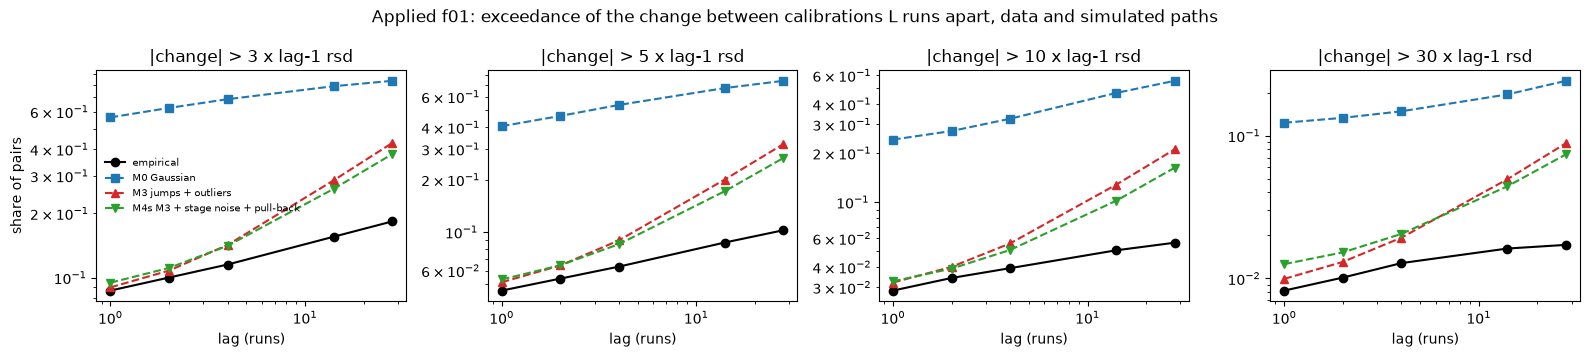

In [15]:
# Models to simulate: M0, M3, BEST and M4s, each once
SIM_MODELS = list(dict.fromkeys(["M0", "M3", BEST, "M4s"]))

# Paths from the in-sample fits on each qubit's own run times, segments and stages
t0 = time.time()
sim = {}
for m in SIM_MODELS:
    sim[m] = jumps.simulate(jumps.natural(th[m]), data, N_SIM, rng)

# Flatten to paths x (qubit, row), and map each (qubit, run) to its flat position
n_cols = data["Y"].shape[1]
flat = {m: s.transpose(1, 0, 2).reshape(N_SIM, -1) for m, s in sim.items()}
ii, kk = np.nonzero(data["index"] >= 0)
lab = data["index"][ii, kk]
run_key = pd.MultiIndex.from_arrays([clean.loc[lab, "qubit"], clean.loc[lab, "run"]])
pos = pd.Series(ii * n_cols + kk, index=run_key)
print(f"simulation time {time.time() - t0:.0f} s")

tail_rows = []
for L in LAGS:
    # Pairs of clean rows L runs apart in one segment, and where they sit in the paths
    p = methods.lag_pairs(clean, ["qubit", "seg"], L, col="y", cuts=CUTS)
    f0 = pos.reindex(pd.MultiIndex.from_arrays([p["qubit"], p["run_0"]])).to_numpy()
    f1 = pos.reindex(pd.MultiIndex.from_arrays([p["qubit"], p["run_0"] + L])).to_numpy()
    span_days = (p["t_1"] - p["t_0"]) / pd.Timedelta("1D")

    # Changes in units of the qubit's lag-1 robust sd: the data, then each model's paths
    scale = s1.loc[p["qubit"]].to_numpy()
    z_emp = np.abs(p["d"].to_numpy()) / scale
    z_mod = {m: np.abs(flat[m][:, f1] - flat[m][:, f0]) / scale for m in SIM_MODELS}

    # Share of pairs beyond each threshold
    for K in K_TAIL:
        row = {
            "lag": L,
            "K": K,
            "pairs": len(p),
            "median_days": np.median(span_days),
            "empirical": np.mean(z_emp > K),
        }
        row |= {m: np.mean(z_mod[m] > K) for m in SIM_MODELS}
        tail_rows.append(row)

tail_tab = pd.DataFrame(tail_rows).set_index(["lag", "K"])
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tail_tab)

# One panel per threshold: the share against lag, for the data and each simulated model
fig, axes = plt.subplots(1, len(K_TAIL), figsize=(4 * len(K_TAIL), 3.6), sharex=True)
for ax, K in zip(axes, K_TAIL):
    t = tail_tab.xs(K, level="K")
    ax.plot(t.index, t["empirical"], "ko-", label="empirical")
    for m, st in zip(SIM_MODELS, ["C0s--", "C3^--", "C2v--", "C1d--"]):
        ax.plot(t.index, t[m], st, label=f"{m} {NAMES[m]}")
    ax.set(
        xscale="log",
        yscale="log",
        xlabel="lag (runs)",
        title=f"|change| > {K} x lag-1 rsd",
    )
axes[0].set_ylabel("share of pairs")
axes[0].legend(frameon=False, fontsize=7)
fig.suptitle(
    "Applied f01: exceedance of the change between calibrations L runs apart, "
    "data and simulated paths"
)
fig.tight_layout()
fig.savefig(FIG / "d2b_ext_tails.png", dpi=130)
plt.show()

**Results.**

- At lag 28 (14 days), the share above 3 robust sd is 0.183 in the data, 0.427 under M3 and 0.379 under M4s. Above 30 it is 0.0172, 0.0885 and 0.0739.
- At lag 1 all three agree (0.087, 0.09 and 0.0947). So the pull-back closes little of the gap at two weeks.


## 13. Do the parameters change over time?

Sections 3 and 10 fit one set of parameters per qubit over two years, through a thermal cycle and several ladder changes. If the parameters change, a single fit goes out of date. We check this in two ways.

- **Rolling fits.** We refit ROLL_MODEL on windows of WINDOW, moved by STEP. The figure shows the median over qubits and the interquartile band.
- **Walk-forward.** From the split date on, we score blocks of BLOCK with three parameter sets, each fitted only on earlier rows. **Fixed** uses the rows before the split date, **expanding** all rows before the block, and **rolling** the ROLL before the block. If the parameters change, the refitted sets should score better.

<details>
<summary><b>Fit details</b></summary>

Every parameter set comes from the same short search (WARM_CYCLES sweeps from WARM_SPAN), starting from the training fit of section 11. So the three sets differ only in the rows they see, and in the first block fixed and expanding are the same fit. Only qubits with MIN_N rows are refitted. A stage's noise ratio is shown only for qubits with MIN_STAGE_ROWS rows of that stage in the window. The filter runs over all rows with each parameter set, and only the block's rows are scored.

</details>


rolling fits: 12 windows, time 95 s


,sqrt_R_kHz,sqrt_q_kHz_per_sqrt_day,J_kHz,jumps_per_30d,O_kHz,outliers_per_100_runs,sd_x_1short,sd_x_2short,tau_days,w,qubits
window_mid,,,,,,,,,,,
2024-05-20,5.62,0.266,25.8,1.56,5.03,5.64,59.6,NaN,19.4,0.0131,29
2024-09-17,4.84,0.0272,10.8,0.92,2.88,6.74,36.4,NaN,6.9,0.0461,29
2024-11-16,5.06,0.01,13.2,0.403,5.15,10.8,28.7,NaN,5.05,0.109,29
2025-01-15,5.17,0.01,9.04,0.518,8.22,12.3,36.9,5.69,3.83,0.0606,30
2025-03-16,4.04,0.0186,16.2,3.7,11.3,12.5,58.9,4.69,4.25,0.0459,30
2025-05-15,3.64,0.243,16.3,3.19,7.41,7.37,40,8.73,6.25,0.102,30
2025-07-14,3.27,0.266,12.7,1.9,7.66,8.32,NaN,8.53,2.74,0.112,30
2025-09-12,3.29,0.266,11.7,0.909,7.2,8.25,NaN,7.97,6.28,0.0279,30
2025-11-11,3.71,0.392,9.6,1.09,7.89,8.46,NaN,12.6,5.74,0.0881,30


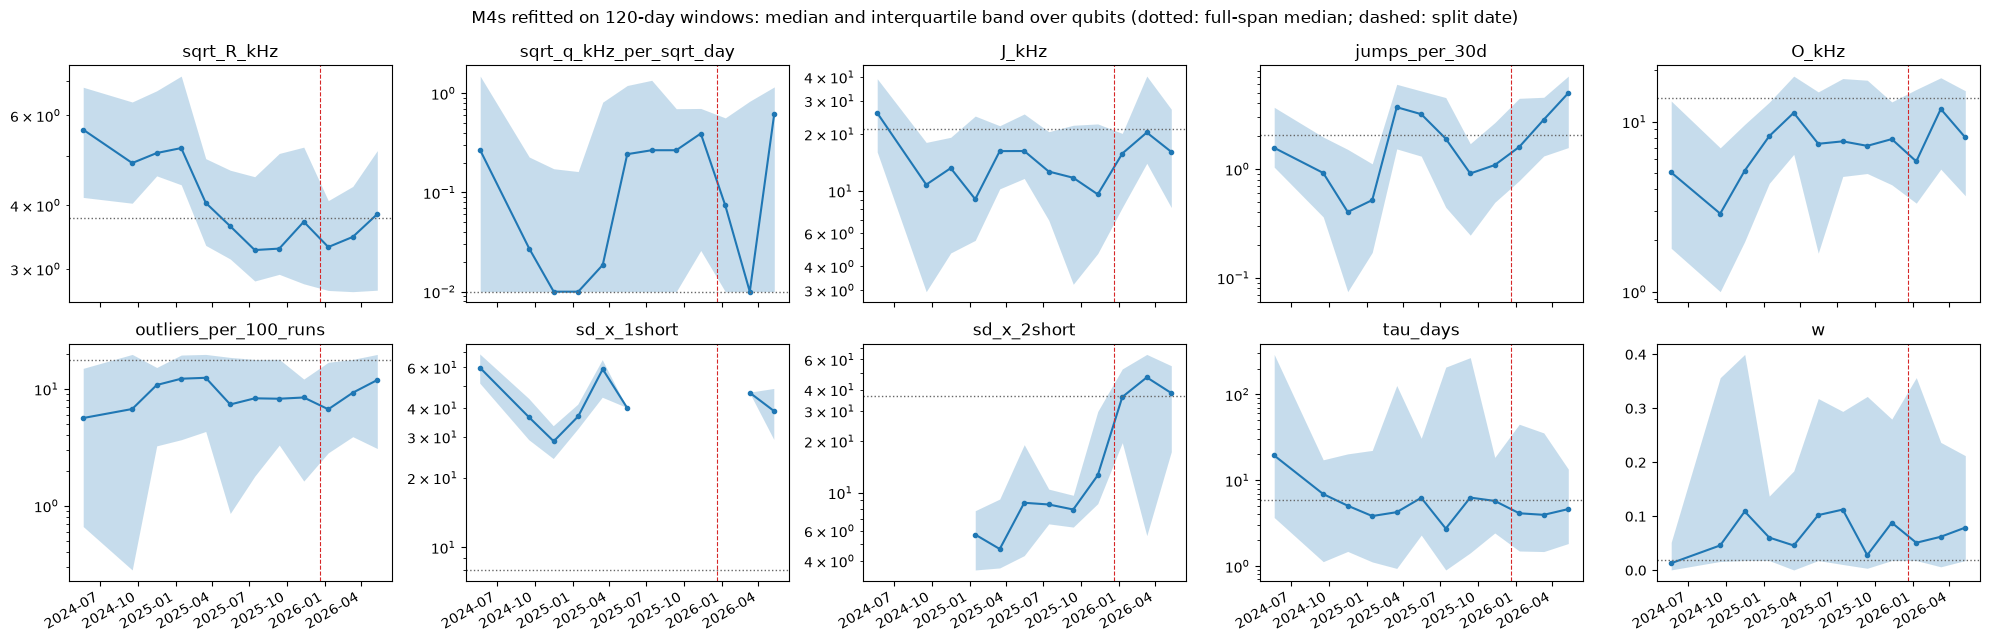

In [16]:
def fit_rows(mask, model: str, start: dict) -> tuple[dict, list]:
    """Refit a model from start on the clean rows in mask.

    Only qubits with MIN_N rows in the mask are refitted; the others keep their start values.
    Returns the parameters of every qubit and the list of refitted qubits.
    """
    # The rows in the mask, on qubits with at least MIN_N of them
    sub = clean[np.asarray(mask)]
    n = sub.groupby("qubit").size()
    sub = sub[sub["qubit"].isin(n[n >= MIN_N].index)]
    if sub.empty:
        return start, []

    # A short coordinate search from those qubits' start values
    d = jumps.panel(sub, np.ones(len(sub), bool))
    at = np.searchsorted(qubits, d["qubits"])
    start_at = {k: v[at] for k, v in start.items()}
    th_s, _ = jumps.fit(d, model, start_at, WARM_CYCLES, WARM_SPAN)

    # Write the refitted values into a copy of the start
    out = {k: v.copy() for k, v in start.items()}
    for k, v in th_s.items():
        out[k][at] = v
    return out, list(d["qubits"])


# Rolling fits: one per window of WINDOW, stepped by STEP, from the in-sample fit
t0 = time.time()
roll = []
window_starts = pd.date_range(clean["t"].min().floor("D"), clean["t"].max() - WINDOW, freq=STEP)
for w0 in window_starts:
    in_win = ((clean["t"] >= w0) & (clean["t"] < w0 + WINDOW)).to_numpy()
    th_w, fq = fit_rows(in_win, ROLL_MODEL, th[ROLL_MODEL])
    if not fq:
        continue

    # Parameters of the refitted qubits
    at_w = np.searchsorted(qubits, fq)
    pw = params({k: v[at_w] for k, v in th_w.items()}, fq)

    # Hide a stage's noise ratio where the window has too few rows of that stage
    ns = (
        clean[in_win]
        .groupby(["qubit", "stage"])
        .size()
        .unstack(fill_value=0)
        .reindex(index=fq, columns=[0, 1, 2], fill_value=0)
    )
    pw.loc[ns[1].to_numpy() < MIN_STAGE_ROWS, "sd_x_1short"] = np.nan
    pw.loc[ns[2].to_numpy() < MIN_STAGE_ROWS, "sd_x_2short"] = np.nan

    roll.append(pw.assign(window_mid=w0 + WINDOW / 2))

roll = pd.concat(roll)
print(f"rolling fits: {roll['window_mid'].nunique()} windows, time {time.time() - t0:.0f} s")

# Median over qubits per window
g = roll.groupby("window_mid")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(g.median().assign(qubits=g.size()))

# One panel per parameter: median and interquartile band over qubits, full-span median, split date
cols = list(par[ROLL_MODEL].columns)
full_med = par[ROLL_MODEL].median()
n_wide = (len(cols) + 1) // 2
fig, axes = plt.subplots(2, n_wide, figsize=(4 * n_wide, 6.5), sharex=True)
for ax, c in zip(axes.flat, cols):
    md_, lo, hi = g[c].median(), g[c].quantile(0.25), g[c].quantile(0.75)
    ax.fill_between(md_.index, lo, hi, color="C0", alpha=0.25, lw=0)
    ax.plot(md_.index, md_, "C0o-", ms=3)
    ax.axhline(full_med[c], color="0.4", ls=":", lw=1)
    ax.axvline(T_SPLIT, color="C3", ls="--", lw=0.8)
    ax.set(title=c, yscale="linear" if c == "w" else "log")
fig.suptitle(
    f"{ROLL_MODEL} refitted on {WINDOW.days}-day windows: median and interquartile band "
    f"over qubits (dotted: full-span median; dashed: split date)"
)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(FIG / "d2b_params_over_time.png", dpi=130)
plt.show()

In [17]:
# Walk-forward for M3, BEST and M4s, on blocks of BLOCK from the split date
WF_MODELS = list(dict.fromkeys(["M3", BEST, "M4s"]))
blocks = pd.date_range(T_SPLIT, clean["t"].max(), freq=BLOCK)
t0 = time.time()
wf_lp, wf_rows = {}, []
for mname in WF_MODELS:
    # Fixed: the training fit with the same short search on the training rows as every refit,
    # so the schemes differ only in their rows
    fix_th, _ = fit_rows(clean["t"] < T_SPLIT, mname, th_tr[mname])

    for b0 in blocks:
        # Expanding: all rows before the block (the fixed fit for the first block)
        if b0 <= T_SPLIT:
            exp_th = fix_th
        else:
            exp_th, _ = fit_rows(clean["t"] < b0, mname, th_tr[mname])

        # Rolling: the ROLL before the block
        in_roll = (clean["t"] >= b0 - ROLL) & (clean["t"] < b0)
        rol_th, _ = fit_rows(in_roll, mname, th_tr[mname])

        # The block's rows, without segment starts or padding
        in_block = (t_row >= np.datetime64(b0)) & (t_row < np.datetime64(b0 + BLOCK))
        blk = data["VALID"] & ~data["START"] & in_block

        # Filter over all rows with each parameter set, and score only the block
        schemes = [("fixed", fix_th), ("expanding", exp_th), ("rolling", rol_th)]
        for scheme, ths in schemes:
            _, r = jumps.run_filter(as_col(ths), data, detail=True)
            lp = np.where(blk, r["logpred"], np.nan)
            wf_lp.setdefault((mname, scheme), []).append(lp)
            wf_rows.append(
                {
                    "model": mname,
                    "scheme": scheme,
                    "block": b0,
                    "rows": int(blk.sum()),
                    "log_score": float(np.nanmean(lp)),
                    "miss_95": miss(r["pit"][blk], 0.05),
                    "miss_99": miss(r["pit"][blk], 0.01),
                }
            )
print(f"walk-forward: {len(blocks)} blocks from {T_SPLIT:%Y-%m-%d}, time {time.time() - t0:.0f} s")

# Log score per block
wf = pd.DataFrame(wf_rows)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(wf.pivot_table(index="block", columns=["model", "scheme"], values="log_score"))

# Per qubit: the mean log score over all blocks
wq = {k: np.nanmean(np.concatenate(v, axis=1), axis=1) for k, v in wf_lp.items()}

# Per model and scheme: the gain over the fixed fit, qubits gaining, and the mean misses
wf_sum = []
for (mname, scheme), v in wq.items():
    gain = v - wq[(mname, "fixed")]
    w_ = wf[(wf["model"] == mname) & (wf["scheme"] == scheme)]
    all_lp = np.concatenate(wf_lp[(mname, scheme)], axis=1)
    wf_sum.append(
        {
            "model": mname,
            "scheme": scheme,
            "rows": int(w_["rows"].sum()),
            "log_score": float(np.nanmean(all_lp)),
            "gain_vs_fixed_median": float(np.nanmedian(gain)),
            "qubits_gaining": int((gain > 0).sum()),
            "miss_95_mean": w_["miss_95"].mean(),
            "miss_99_mean": w_["miss_99"].mean(),
        }
    )
with pd.option_context("display.float_format", "{:.4g}".format):
    display(pd.DataFrame(wf_sum).set_index(["model", "scheme"]))

walk-forward: 5 blocks from 2025-12-20, time 579 s


model             M3                      M4s               
scheme     expanding  fixed rolling expanding  fixed rolling
block                                                       
2025-12-20    -3.283 -3.283  -3.247    -3.255 -3.255  -3.228
2026-02-18    -3.804 -3.804  -3.991    -3.781 -3.778  -3.914
2026-04-19    -4.188 -4.246  -4.246    -4.119  -4.21  -4.168
2026-06-18     -4.15 -4.387  -4.049    -4.019 -4.311  -3.979
2026-08-17    -4.159 -5.017  -4.108    -4.483 -5.265  -4.144

rows  log_score  gain_vs_fixed_median  qubits_gaining  miss_95_mean  miss_99_mean
model scheme                                                                                       
M3    fixed      12249      -3.94                     0               0        0.1023       0.04797
      expanding  12249     -3.854               0.01528              25       0.08348       0.03044
      rolling    12249     -3.862              0.005608              17        0.0973       0.03752
M4s   fixed      12249     -3.899                     0               0         0.102       0.04776
      expanding  12249     -3.791               0.01422              28       0.07608       0.02893
      rolling    12249     -3.804               0.00805              16       0.09128       0.03699

**Results.**

- **Rolling fits.** The median $\sqrt{R}$ is 4.84 to 5.62 kHz in windows up to early 2025, and 3.27 to 4.04 kHz after. Jumps per 30 days range from 0.403 to 4.99.
- **Walk-forward.** An expanding refit gains 0.0153 nats over the fixed fit for M3 (25 qubits) and 0.0142 for M4s (28). Rolling gains less. The gap grows in the later blocks.
- The mean 95% miss falls from 0.102 (fixed) to 0.083 (expanding) for M3, and from 0.102 to 0.076 for M4s. So the expanding refit helps, but doesn't bring the miss down to 0.05.


## 14. Setpoint replay

The producer applies each run's measurement as the new f01. The model's filtered level combines the run with the qubit's history, so it has less of the run's noise, but it follows a real jump more slowly. Each rule below sets the setpoint after a run. Its error is the next run's measurement minus that setpoint.

- **Existing.** Set to the measurement.
- **Model level.** The filtered level of M3 and of BEST.
- **Hybrid.** Keep the model level, unless the measurement is more than a threshold away. Then take the measurement, because a large move is more likely a real jump.
- **Revert on warn.** A run that warns keeps the old setpoint. This helps if warnings are single bad fits, and hurts if they come in streaks.
- **Deadband with gain.** With $\Delta$ the change from the current setpoint: no move when $\lvert\Delta\rvert < d$, a share $g$ of $\Delta$ up to RESET_KHZ, and the full measurement above it. Most of a small $\Delta$ is the run's noise.
- **Both.** Revert on warn, then the deadband with gain.

We choose $d$ and $g$ on the training intervals. The main score is the **setpoint rms**: on core intervals (every rule within CORE_KHZ of the next run) whose next run is a full ladder with no warning, the rms error with the next run's noise variance subtracted.

<details>
<summary><b>Scores and replay set-up</b></summary>

- **Choosing $d$ and $g$.** By the mean absolute error on the training intervals, with each error capped at CORE_KHZ, so a few errors of several MHz don't decide the choice.
- **Scores.** The median absolute error, the share above 20 kHz, the mean absolute error, the rms, the core rms, and the number of qubits where the rule's median absolute error is below the existing rule's.
- **Setpoint rms.** The next run's noise variance is $R_t$ of BEST for its stage. Next runs that stopped short are left out, because their noise sd is several times larger and the CORE_KHZ window cuts it off.
- **Large errors.** The share of the existing rule's squared error in its largest errors, and how often a warned run is followed by another.
- **Replay.** The parameters are the training fits of section 11. Test intervals start from the split date and join consecutive runs of a segment at most MAX_GAP_DAYS apart. The replay uses the measured values as they were, so it can't show how a different setpoint would change the next run's ladder.

</details>


training capped mean |error| (kHz) by deadband (rows) and gain (columns):
without revert:


g,0.100,0.250,0.500,0.750,1.000
d_kHz,,,,,
0,7.678,7.111,7.113,7.361,7.820
5,7.762,7.173,7.166,7.397,7.826
10,8.245,7.576,7.454,7.660,8.065
15,9.041,8.360,8.107,8.130,8.457


with revert on warn:


g,0.100,0.250,0.500,0.750,1.000
d_kHz,,,,,
0,7.621,7.147,7.174,7.426,7.880
5,7.708,7.209,7.225,7.459,7.888
10,8.184,7.603,7.510,7.724,8.125
15,8.953,8.357,8.148,8.189,8.509


chosen: d = 0 kHz, g = 0.25
chosen with revert: d = 0 kHz, g = 0.25
test intervals 12189 on 30 qubits; with a clean next run 11422; core intervals 10722, with a clean next run 10614; next-run noise sd, mean: core 7.96 kHz, core with a clean next run 5.61 kHz


,median_abs_kHz,share_over_20kHz,mean_abs_kHz,rms_kHz,clean_next_share_over_20kHz,clean_next_rms_kHz,core_rms_kHz,core_setpoint_rms_kHz,qubits_better
existing: set to measured,4.522,0.1391,27.61,345.2,0.09771,247.9,8.131,5.738,0
revert on warn,4.53,0.1411,34.68,491.6,0.09298,339.9,8.174,5.736,4
"deadband 0 kHz, gain 0.25",4.248,0.1212,27.09,345.2,0.08072,247.8,7.394,4.702,22
"revert + deadband 0 kHz, gain 0.25",4.25,0.1236,34.16,491.7,0.07407,339.9,7.433,4.605,21
M3 level,4.04,0.1195,28.53,434.4,0.08037,279.8,7.177,4.373,28
M3 hybrid 20 kHz,4.04,0.1214,26.92,345.1,0.08116,247.8,7.243,4.454,27
M3 hybrid 50 kHz,4.035,0.1185,26.75,344.8,0.07906,247.4,7.177,4.373,28
M4s level,4.082,0.1185,27.63,378.8,0.07783,316.5,7.203,4.431,28
M4s hybrid 20 kHz,4.079,0.1222,26.94,345.1,0.08125,247.8,7.27,4.501,27
M4s hybrid 50 kHz,4.075,0.1188,26.75,345.1,0.07932,247.8,7.204,4.431,28


existing rule, |error| > 50 kHz: 6.33% of test intervals, 99.9% of the squared error
existing rule, |error| > 200 kHz: 2.06% of test intervals, 99.5% of the squared error
existing rule, |error| > 1000 kHz: 0.22% of test intervals, 97.3% of the squared error
warned test runs 760; followed by a warned run: 0.82 (all test runs: 0.06)


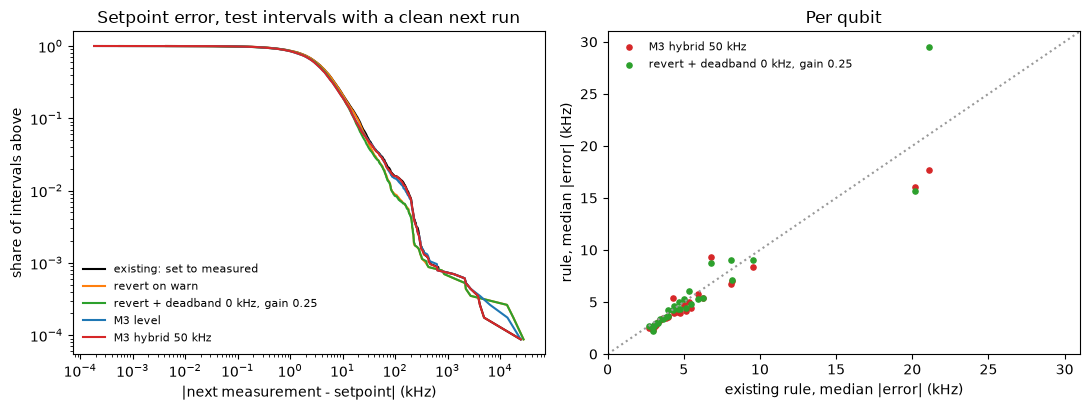

In [18]:
# The applied values, and a warned flag per panel row
Y = data["Y"]
valid_idx = data["index"] >= 0
WARN = np.zeros_like(data["VALID"])
WARN[valid_idx] = clean["warned"].to_numpy()[data["index"][valid_idx]]

# An interval joins a row to the next one in its segment, at most MAX_GAP_DAYS later
gap_ok = data["VALID"][:, 1:] & ~data["START"][:, 1:] & (data["DT"][:, 1:] <= MAX_GAP_DAYS)

# Test intervals start from the split date; a clean next run is a full ladder with no warning
nxt = gap_ok & (t_row[:, :-1] >= np.datetime64(T_SPLIT))
clean_next = (data["STAGE"][:, 1:] == 0) & ~WARN[:, 1:]


def stateless(d: float, g: float, revert: bool) -> np.ndarray:
    """Setpoint after each run under a deadband d (kHz) and gain g, optionally reverting on warn.

    A change of at least RESET_KHZ is taken in full; each segment starts from its first value.
    """
    u = Y.copy()
    for k in range(1, Y.shape[1]):
        # The run's change against the current setpoint, and the share of it to apply
        delta = Y[:, k] - u[:, k - 1]
        a = np.abs(delta)
        gain = np.where(a >= RESET_KHZ, 1.0, np.where(a >= d, g, 0.0))

        # A warned run keeps the old setpoint
        if revert:
            gain = np.where(WARN[:, k], 0.0, gain)

        u[:, k] = np.where(data["START"][:, k], Y[:, k], u[:, k - 1] + gain * delta)
    return u


def capped(u: np.ndarray, m) -> float:
    """Mean absolute error of setpoint u against the next run over intervals m, capped at CORE_KHZ."""
    err = np.abs(Y[:, 1:] - u[:, :-1])
    return float(np.mean(np.minimum(err[m], CORE_KHZ)))


# Score the deadband and gain grid on the training intervals, with and without revert
train_iv = gap_ok & (t_row[:, :-1] < np.datetime64(T_SPLIT))
grid_rows = []
for r in (False, True):
    for d in DEADBAND_KHZ:
        for g in GAIN:
            grid_rows.append(
                {
                    "revert": r,
                    "d_kHz": d,
                    "g": g,
                    "train_capped_abs_kHz": capped(stateless(d, g, r), train_iv),
                }
            )
grid = pd.DataFrame(grid_rows)

print("training capped mean |error| (kHz) by deadband (rows) and gain (columns):")
for r, gr in grid.groupby("revert"):
    print("with revert on warn:" if r else "without revert:")
    with pd.option_context("display.float_format", "{:.3f}".format):
        display(gr.pivot(index="d_kHz", columns="g", values="train_capped_abs_kHz"))

# The best deadband and gain, with and without revert
pick = {r: gr.loc[gr["train_capped_abs_kHz"].idxmin()] for r, gr in grid.groupby("revert")}
for r, p in pick.items():
    print(f"chosen{' with revert' if r else ''}: d = {p['d_kHz']:g} kHz, g = {p['g']:g}")

# The stateless rules: existing, revert on warn, deadband with gain, and both
base = "existing: set to measured"
rev = "revert on warn"
dg = f"deadband {pick[False]['d_kHz']:g} kHz, gain {pick[False]['g']:g}"
both = f"revert + deadband {pick[True]['d_kHz']:g} kHz, gain {pick[True]['g']:g}"
U = {
    base: Y,
    rev: stateless(0, 1, True),
    dg: stateless(pick[False]["d_kHz"], pick[False]["g"], False),
    both: stateless(pick[True]["d_kHz"], pick[True]["g"], True),
}

# The model rules: the level of M3 and BEST, and hybrids that take a measurement far from it
for m in dict.fromkeys(["M3", BEST]):
    lev = rec_tr[m]["level"]
    U[f"{m} level"] = lev
    for h in HYBRID_KHZ:
        far = np.abs(Y - lev) > h
        U[f"{m} hybrid {h} kHz"] = np.where(far, Y, lev)

# Each rule's error: the next run's value minus the setpoint left by this run
E = {n: Y[:, 1:] - u[:, :-1] for n, u in U.items()}

# Core: test intervals where every rule is within CORE_KHZ of the next run
core = nxt.copy()
for e in E.values():
    core &= np.abs(e) < CORE_KHZ

# The same with a clean next run, and the next run's noise variance under BEST
nc = nxt & clean_next
core_c = core & clean_next
R_next = rec_tr[BEST]["R_t"][:, 1:]
noise_var = np.mean(R_next[core_c])

# Median absolute error per qubit on the test intervals
q_med = {n: np.nanmedian(np.where(nxt, np.abs(e), np.nan), axis=1) for n, e in E.items()}

# Scores per rule; the setpoint rms takes the next run's noise out on clean-next core intervals
rep_rows = {}
for n, e in E.items():
    abs_test = np.abs(e[nxt])
    rep_rows[n] = {
        "median_abs_kHz": np.median(abs_test),
        "share_over_20kHz": np.mean(abs_test > 20),
        "mean_abs_kHz": np.mean(abs_test),
        "rms_kHz": np.sqrt(np.mean(e[nxt] ** 2)),
        "clean_next_share_over_20kHz": np.mean(np.abs(e[nc]) > 20),
        "clean_next_rms_kHz": np.sqrt(np.mean(e[nc] ** 2)),
        "core_rms_kHz": np.sqrt(np.mean(e[core] ** 2)),
        "core_setpoint_rms_kHz": np.sqrt(max(np.mean(e[core_c] ** 2) - noise_var, 0)),
        "qubits_better": int((q_med[n] < q_med[base]).sum()),
    }
rep = pd.DataFrame(rep_rows).T

sd_core = np.sqrt(np.mean(R_next[core]))
sd_core_c = np.sqrt(np.mean(R_next[core_c]))
print(
    f"test intervals {int(nxt.sum())} on {int(nxt.any(axis=1).sum())} qubits; "
    f"with a clean next run {int(nc.sum())}; "
    f"core intervals {int(core.sum())}, with a clean next run {int(core_c.sum())}; "
    f"next-run noise sd, mean: "
    f"core {sd_core:.2f} kHz, core with a clean next run {sd_core_c:.2f} kHz"
)
with pd.option_context("display.float_format", "{:.4g}".format):
    display(rep)

# How much of the existing rule's squared error sits in its largest errors
e0 = E[base][nxt]
for thr in [50, 200, 1000]:
    big = np.abs(e0) > thr
    ss_share = np.sum(e0[big] ** 2) / np.sum(e0**2)
    print(
        f"existing rule, |error| > {thr} kHz: {big.mean():.2%} of test intervals, "
        f"{ss_share:.1%} of the squared error"
    )

# Warning streaks: how often a warned test run is followed by another warned run
w_run = WARN[:, :-1] & gap_ok & (t_row[:, :-1] >= np.datetime64(T_SPLIT))
next_warned = WARN[:, 1:]
print(
    f"warned test runs {int(w_run.sum())}; "
    f"followed by a warned run: {next_warned[w_run].mean():.2f} "
    f"(all test runs: {next_warned[nxt].mean():.2f})"
)

# Left: share of clean-next test intervals above each error, per rule
hyb = f"M3 hybrid {HYBRID_KHZ[-1]} kHz"
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for n, c in [(base, "k"), (rev, "C1"), (both, "C2"), ("M3 level", "C0"), (hyb, "C3")]:
    a = np.sort(np.abs(E[n][nc]))
    ax[0].plot(a, 1 - np.arange(len(a)) / len(a), color=c, label=n)
ax[0].set(
    xscale="log",
    yscale="log",
    xlabel="|next measurement - setpoint| (kHz)",
    ylabel="share of intervals above",
    title="Setpoint error, test intervals with a clean next run",
)
ax[0].legend(frameon=False, fontsize=8)

# Right: per-qubit median absolute error against the existing rule's
for n, c in [(hyb, "C3"), (both, "C2")]:
    ax[1].scatter(q_med[base], q_med[n], s=14, color=c, label=n)
lim = [0, np.nanmax([q_med[base], q_med[hyb], q_med[both]]) * 1.05]
ax[1].plot(lim, lim, color="0.6", ls=":")
ax[1].set(
    xlim=lim,
    ylim=lim,
    xlabel="existing rule, median |error| (kHz)",
    ylabel="rule, median |error| (kHz)",
    title="Per qubit",
)
ax[1].legend(frameon=False, fontsize=8)

fig.tight_layout()
fig.savefig(FIG / "d2b_setpoint.png", dpi=130)
plt.show()

**Results.**

- On the training intervals, the best choice is a deadband of 0 kHz and a gain of 0.25, with and without revert. There are 12,189 test intervals, and 10,614 are core intervals with a clean next run.

| Rule | Median (kHz) | rms (kHz) | Core rms (kHz) | Setpoint rms (kHz) | Qubits better |
|---|---|---|---|---|---|
| existing | 4.522 | 345.2 | 8.131 | 5.738 | |
| revert on warn | | 491.6 | 8.174 | 5.736 | 4 |
| deadband 0, gain 0.25 | 4.248 | 345.2 | 7.394 | 4.702 | 22 |
| revert plus gain 0.25 | | | | 4.605 | |
| M3 level | 4.04 | 434.4 | 7.177 | 4.373 | 28 |
| M3 hybrid 50 kHz | 4.035 | 344.8 | 7.177 | 4.373 | 28 |
| M4s hybrid 50 kHz | 4.075 | 345.1 | 7.204 | 4.431 | 28 |

- For the existing rule, errors above 200 kHz are 2.06% of test intervals and hold 99.5% of the squared error.
- Of 760 warned test runs, 0.82 are followed by another warned run, against 0.06 for all test runs. So warnings come in streaks, and reverting keeps an out-of-date value.


## 15. Is the gap at two weeks a change of rate over time?

Section 12 finds M3 at more than twice the data's share of large changes at 14 days, and the pull-back doesn't close the gap. If large moves are more frequent in some periods, a fit over the whole span gives quiet periods the jumps of busy ones. [d2a](d2a_f01_jumps_coherence.ipynb), section 8, compares the rates across windows.

**Test.** We refit M3 in each of d2a's windows A to D (A and B before the thermal cycle, C and D after it). In each window we compute the section 12 share from the data, from the full-span M3 paths, and from paths simulated with the window's fit. If a changing rate is the cause, the window fits match the data at 14 days.

<details>
<summary><b>Set-up</b></summary>

We refit M3 with WARM_CYCLES sweeps from the full-span fit, on the window's clean rows for qubits with MIN_N rows, and simulate N_SIM paths per qubit on the window's own rows. Pairs come from `methods.lag_pairs` on the window's rows, cut at CUTS. Changes are scaled by the full-span lag-1 robust sd. "all" pools the pairs of the four windows.

</details>


In [19]:
# d2a's windows: A and B before the thermal cycle, C and D after it, each W long (D to the end)
inc0 = periods.INCIDENTS[0].period[0]
settled = periods.SETTLING[0][1]
inc1 = periods.INCIDENTS[1].period
W = inc1[0] - settled
WIN = {
    "A": (inc0 - 2 * W, inc0 - W),
    "B": (inc0 - W, inc0),
    "C": (settled, inc1[0]),
    "D": (inc1[1], clean["t"].max() + pd.Timedelta("1s")),
}

t0 = time.time()
win_rows, win_par = [], {}
for wname, span in WIN.items():
    # The window's clean rows, on qubits with at least MIN_N of them
    sub = clean[periods.within(clean["t"], span)]
    nq = sub.groupby("qubit").size()
    sub = sub[sub["qubit"].isin(nq[nq >= MIN_N].index)]

    # Refit M3 from the full-span fit, and keep the median parameters
    d_w = jumps.panel(sub, np.ones(len(sub), bool))
    at = np.searchsorted(qubits, d_w["qubits"])
    start_w = {k: v[at] for k, v in th["M3"].items()}
    th_w, _ = jumps.fit(d_w, "M3", start_w, WARM_CYCLES, WARM_SPAN)
    win_par[wname] = params(th_w, d_w["qubits"]).median().rename(wname)
    win_par[wname]["qubits"] = len(d_w["qubits"])

    # Paths from the window's fit on its own rows, flattened and indexed as in section 12
    s_w = jumps.simulate(jumps.natural(th_w), d_w, N_SIM, rng)
    s_w = s_w.transpose(1, 0, 2).reshape(N_SIM, -1)
    i_w, k_w = np.nonzero(d_w["index"] >= 0)
    lab_w = d_w["index"][i_w, k_w]
    key_w = pd.MultiIndex.from_arrays([clean.loc[lab_w, "qubit"], clean.loc[lab_w, "run"]])
    pos_w = pd.Series(i_w * d_w["Y"].shape[1] + k_w, index=key_w)

    for L in WIN_LAGS:
        # Pairs inside the window, and where they sit in the full-span and window paths
        p = methods.lag_pairs(sub, ["qubit", "seg"], L, col="y", cuts=CUTS)
        k0 = pd.MultiIndex.from_arrays([p["qubit"], p["run_0"]])
        k1 = pd.MultiIndex.from_arrays([p["qubit"], p["run_0"] + L])
        full_0 = pos.reindex(k0).to_numpy(int)
        full_1 = pos.reindex(k1).to_numpy(int)
        win_0 = pos_w.reindex(k0).to_numpy(int)
        win_1 = pos_w.reindex(k1).to_numpy(int)

        # Changes in units of the full-span lag-1 robust sd
        scale = s1.loc[p["qubit"]].to_numpy()
        z = {
            "empirical": np.abs(p["d"].to_numpy()) / scale,
            "M3_full_span": np.abs(flat["M3"][:, full_1] - flat["M3"][:, full_0]) / scale,
            "M3_window": np.abs(s_w[:, win_1] - s_w[:, win_0]) / scale,
        }

        # Share of pairs beyond each threshold
        for K in WIN_K:
            row = {
                "window": wname,
                "lag": L,
                "K": K,
                "pairs": len(p),
                "qubits": p["qubit"].nunique(),
            }
            row |= {n: np.mean(v > K) for n, v in z.items()}
            win_rows.append(row)

print(f"window length {W.days} days; fit and simulation time {time.time() - t0:.0f} s")
print("median M3 parameters per window:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(win_par).T)

# Pool the windows: shares weighted by each window's pairs
win_tab = pd.DataFrame(win_rows)
share_cols = ["empirical", "M3_full_span", "M3_window"]
pairs_all = win_tab.groupby(["lag", "K"])["pairs"].sum()
pooled = (
    win_tab[share_cols]
    .mul(win_tab["pairs"], axis=0)
    .groupby([win_tab["lag"], win_tab["K"]])
    .sum()
    .div(pairs_all, axis=0)
)
pooled["pairs"] = pairs_all

# Per window, then "all", with the window fit over the data
pooled_rows = (
    pooled.assign(window="all")
    .set_index("window", append=True)
    .reorder_levels(["window", "lag", "K"])
)
win_tab = pd.concat([win_tab.set_index(["window", "lag", "K"]), pooled_rows])
win_tab["window_over_empirical"] = win_tab["M3_window"] / win_tab["empirical"]
with pd.option_context("display.float_format", "{:.3g}".format):
    display(win_tab)

window length 89 days; fit and simulation time 20 s
median M3 parameters per window:


,sqrt_R_kHz,sqrt_q_kHz_per_sqrt_day,J_kHz,jumps_per_30d,O_kHz,outliers_per_100_runs,qubits
A,3.61,0.0788,6.67,1.35,9.44,9.27,30
B,3.25,0.118,15.1,1.52,5.43,4.67,30
C,3.96,0.373,13.3,4.72,7.66,13,30
D,4.79,0.0221,12.7,3.21,10.3,8.82,30


pairs  qubits  empirical  M3_full_span  M3_window  window_over_empirical
window lag K                                                                           
A      1   3    5154      30     0.0681        0.0894     0.0685                   1.01
           30   5154      30    0.00291        0.0101    0.00377                   1.29
       14  3    4794      30      0.107         0.282      0.135                   1.27
           30   4794      30    0.00375         0.049     0.0229                   6.11
       28  3    4375      30      0.126         0.425      0.191                   1.51
           30   4375      30    0.00457        0.0884     0.0411                   8.99
B      1   3    5158      30     0.0376        0.0897     0.0372                   0.99
           30   5158      30   0.000194        0.0102   0.000698                    3.6
       14  3    4379      30     0.0687         0.283      0.152                   2.21
           30   4379      30   0.000457        0.0487     0.0079                   17.3
       28  3    3749      30     0.0928         0.429      0.241                    2.6
           30   3749      30   0.000533        0.0876     0.0162                   30.4
C      1   3    5004      30      0.145        0.0894      0.125                   0.86
           30   5004      30       0.02        0.0102     0.0164                   0.82
       14  3    4152      30      0.261          0.28      0.315                   1.21
           30   4152      30     0.0361        0.0502     0.0538                   1.49
       28  3    3312      30      0.312         0.423      0.415                   1.33
           30   3312      30     0.0405        0.0899     0.0834                   2.06
D      1   3    2514      30      0.171        0.0899      0.149                  0.875
           30   2514      30     0.0263       0.00969     0.0173                  0.658
       14  3    2125      30      0.299         0.279      0.336                   1.12
           30   2125      30     0.0546        0.0486     0.0793                   1.45
       28  3    1735      30      0.349         0.419      0.416                   1.19
           30   1735      30     0.0651        0.0881       0.12                   1.85
all    1   3   17830     NaN     0.0953        0.0896     0.0866                  0.909
           30  17830     NaN     0.0102        0.0101    0.00833                  0.816
       14  3   15450     NaN      0.164         0.281      0.216                   1.32
           30  15450     NaN     0.0185        0.0492     0.0347                   1.88
       28  3   13171     NaN      0.193         0.425      0.291                   1.51
           30  13171     NaN     0.0204        0.0885     0.0551                    2.7

**Results.**

- Each window is 89 days long. M3's median jumps per 30 days are 1.35 and 1.52 in A and B, and 4.72 and 3.21 in C and D.
- Pooled over the windows, the share above 3 robust sd at lag 28 is 0.193 in the data, 0.425 under full-span M3 and 0.291 under window M3.
- Window M3 over the data at lag 28 is 1.51, 2.6, 1.33 and 1.19 in A to D. So the window fits close about half of the gap, and every window still predicts too many large changes.


## 16. Conclusion

**Verdict: partly holds.** Jumps and outliers fit the applied f01 much better than a Gaussian random walk, and predict the next run better. But M3 predicts too many large changes over two weeks, and no extension fixes this. Its intervals are too wide before the thermal cycle and too narrow after it, and an expanding refit narrows the gap. As a setpoint, a hybrid or a gain of 0.25 lowers the typical error, while a few large errors still set the overall rms.

| Result | Status |
|---|---|
| M3 is best by AIC on all 30 qubits and by BIC on 27. The median $\Delta\text{AIC}$ against M0 is −3346 (section 3) | Jumps and outliers are needed |
| Out of sample, M3 gains 1.434 nats per test row over M0 on all 30 qubits. It misses 0.031 of rows at 95% before the thermal cycle and 0.1415 after it (section 4) | Better prediction. Intervals too wide before the cycle and too narrow after it |
| Above 3 robust sd, M3 matches the data at lag 1 (0.09 against 0.087). At lag 28 (14 days) it predicts 0.427 against 0.183 (section 5) | M3 overstates how stale a calibration gets |
| 2,887 runs are labelled outliers (0.84 revert) and 1,049 jumps (0.0308 revert). About half the fitted jumps get no label (section 6) | Most large moves are outliers |
| The applied f01 averages down to 11 kHz at 16 days, while M3 predicts a rise. With jumps and outliers out it is flat at about 5 kHz from 4 days on (section 7) | Jumps don't add up like a random walk. A $1/f$ part is possible |
| The median change is 4.45 kHz on full-ladder runs, 82 kHz one step short and 33.9 kHz two or more short. Stage noise lowers the median AIC by 40 against M3 (sections 8 and 10) | A run's noise depends on its FineFrequency stage |
| The pull-back raises the median AIC by 2.1, and $w$ is below 0.05 on 20 qubits. At 14 days, M4s predicts 0.379 against M3's 0.427 and the data's 0.183 (sections 10 and 12) | Jumps don't decay. The pull-back doesn't explain the gap |
| An expanding refit gains 0.015 nats over the fixed fit for M3 (25 qubits), and the mean 95% miss falls from 0.102 to 0.083 (section 13) | The parameters change. Refit with all past data |
| The setpoint rms falls from 5.738 kHz (existing) to 4.373 kHz (M3 hybrid 50 kHz, 28 qubits better) and 4.702 kHz (gain 0.25, 22 qubits). The M3 level alone raises the overall rms to 434 kHz (section 14) | The hybrid and gain 0.25 are better setpoints on typical runs |
| Revert on warn raises the rms to 492 kHz, and 0.82 of warned runs are followed by another (section 14) | Revert on warn doesn't help |
| Errors above 200 kHz are 2.06% of intervals and hold 99.5% of the existing rule's squared error (section 14) | No setpoint rule reaches the large errors |
| Window fits lower the lag-28 share from 0.425 to 0.291, against the data's 0.193. Jumps per 30 days are 1.35 and 1.52 before the thermal cycle and 4.72 and 3.21 after it (section 15) | A changing rate explains part of the gap, not all of it |

<details>
<summary><b>Other checks</b></summary>

| Result | Status |
|---|---|
| M3's $\sqrt{R}$ is 1.66 times the B3c fit sd (section 3) | The run's noise is larger than its fit sd |
| Out of sample, M4s gains 0.0047 nats over M3 (23 qubits), and no more than 0.006 in either period. Stage noise lowers the 95% miss on runs two or more short from 0.54 to 0.41 (section 11) | Small gain. BEST is M4s |

</details>


## 17. Next steps (TODO)

The modelling is done. What's left is a recommendation, with a clear statement of where it helps.

- **Write the recommendation.** Two options, both scored by the setpoint rms (section 14):
  - **Gain 0.25.** Move a quarter of the way to each new measurement, and take the full measurement when the change is above 50 kHz. The setpoint rms falls from 5.738 to 4.702 kHz. It needs no stored state, so it is a few lines in calibrate_1q.
  - **M3 hybrid.** Use the model level, but take the measurement when it is more than 50 kHz away. The setpoint rms falls to 4.373 kHz. It needs the filter running per qubit and an expanding refit (section 13).
  - The note should give the rule, where it goes in calibrate_1q (after the Ramsey and FineFrequency steps), the expected gain and the limits below.
- **Say where the gain matters.** It matters for long or idle-heavy circuits, not single gates. The archive's benchmarks run soon after calibration, so they won't show it.
- **Test it on the device, if it goes ahead.** On a few qubits, switch between the existing rule and the chosen rule at each calibration. Measure the detuning with a short Ramsey some hours after each calibration, or run an idle-heavy benchmark.
- **Don't expect it to fix the large errors.** Errors above 200 kHz hold 99.5% of the squared error (section 14). They come from the controller states studied in D3: warning streaks ([d3c](d3c_warning_streaks.ipynb)), the carried frequency offset ([d3a](d3a_calibrate_1q_ladders.ipynb)) and the DRAG reset ([d3b](d3b_drag_trap.ipynb)).
- **Don't use M3's drift for the recalibration interval yet.** M3 predicts too many large changes at two weeks, even per window (sections 5, 12 and 15). [d2a](d2a_f01_jumps_coherence.ipynb) finds that most large moves sit next to a warned run (section 1), and that the excess of moves that return comes from these (section 6). M3 may read such a move as a lasting jump. So refit M3 on clean moves only, or use the data's own exceedance curves. The cost of skipping runs is in [d3a](d3a_calibrate_1q_ladders.ipynb), section 7.
